# 47 -- MAE-only full-data retrain, raw and corrected

**Scope: build and validate only. `SEND = False`, and it stays `False`. Nothing is sent.**

Notebook 39 (2026-10-02) recorded `mae_only` as one of three arms that exist only as a
cross-validation screen and had never been retrained on full data. This notebook closes that gap
for `mae_only` alone: one full-data fit, blind predictions, a sanity check against the best
submission on record, and the project's own already board-validated corrections applied as clearly
separated layers.

`mae_only` matters for one specific reason. Notebook 31 introduced it as the decomposition arm for
`deadzone`, to separate a loss-function effect from a clipped-target effect. `deadzone` carries a
structural fold-crosstalk caveat (its training target comes from an out-of-fold donor model that
was itself trained on the fold being held out), and notebooks 31, 34, 35 and 37 all state that its
measured magnitude is plausibly optimistic as a result. `mae_only` carries **none** of that: its
target is the literal curated label, and the only thing that changes is the loss function. It is
the clean, leak-free half of the `deadzone` effect, and at 25 cluster-disjoint folds it is
significantly better than `plain` on CYP1A2 and CYP2D6.

**Protected, never opened or executed:** `notebooks/32_deadzone_aid_retrain.ipynb` and
`notebooks/40_single_object_ensemble.ipynb`. Both carry live submission code. Their saved outputs
are read read-only.

In [1]:
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO_ROOT))

import glob
import hashlib
import importlib.metadata
import json
import os
import re
import subprocess
import time
from datetime import datetime, timezone

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import pearsonr, spearmanr

from src.chemprop_screen import (
    run_chemprop_predict,
    run_chemprop_train,
    setup_logging,
    verify_predictions,
)
from src.vendor.openadmet_eval.config import REGRESSION_ENDPOINTS
from src.vendor.validation.activity_validation import validate_activity_submission

# Notebook 34 established that restricting BLAS/OMP to one thread changes the floating-point
# reduction order and so the training trajectory: its sanity check came back 0.0378 ST-RAE off
# notebook 05's stored numbers with OMP_NUM_THREADS=1 and bit-identical with it unset. Asserted
# here at the top of a fresh kernel, BEFORE any import that might set one.
# KMP_DUPLICATE_LIB_OK is reported rather than asserted: notebook 40 established that
# `import xgboost` sets it, and this notebook does not import xgboost, but torch/chemprop inherit
# whatever is already set and the variable has no effect on the training trajectory.
assert "OMP_NUM_THREADS" not in os.environ, (
    f"OMP_NUM_THREADS is set to {os.environ.get('OMP_NUM_THREADS')!r}. Notebook 34 established "
    "this changes the training trajectory. Unset it and restart the kernel."
)
print(f"OMP_NUM_THREADS unset: True")
print(f"KMP_DUPLICATE_LIB_OK: {os.environ.get('KMP_DUPLICATE_LIB_OK', '<unset>')} (reported, not asserted)")

print(f"\npython: {sys.version.split()[0]}")
for pkg in ["numpy", "pandas", "matplotlib", "scipy", "rdkit", "chemprop", "torch"]:
    try:
        print(f"{pkg}: {importlib.metadata.version(pkg)}")
    except importlib.metadata.PackageNotFoundError:
        pass

ISOFORMS = [e.split("_")[0] for e in REGRESSION_ENDPOINTS]
PIC50_COL = {iso: f"{iso}_pIC50_direct_inhibition" for iso in ISOFORMS}

OUT = REPO_ROOT / "outputs" / "47_mae_only_full_retrain"
FIG_OUT = OUT / "figures"
CHEMPROP_RUNS_DIR = OUT / "chemprop_runs"
LOG_DIR = REPO_ROOT / "logs" / "47_mae_only_full_retrain"
for d in [OUT, FIG_OUT, CHEMPROP_RUNS_DIR, LOG_DIR]:
    d.mkdir(parents=True, exist_ok=True)

CURATED_PATH = REPO_ROOT / "data" / "processed" / "train_inhibition_curated.csv"
BLIND_PATH = REPO_ROOT / "data" / "processed" / "test_blinded_curated.csv"

NB35_OUT = REPO_ROOT / "outputs" / "35_butina_repeat3"
NB37_OUT = REPO_ROOT / "outputs" / "37_butina_5x5_complete"
NB36_OUT = REPO_ROOT / "outputs" / "36_spread_corrected_nb32a"
NB39_OUT = REPO_ROOT / "outputs" / "39_ambiguity_and_shared_blend"
NB27B_SUB = REPO_ROOT / "outputs" / "27b_aid_cyp2d6_corrected" / "submission_candidate.csv"
NB10C_SUB = REPO_ROOT / "outputs" / "10c_control_submission" / "submission_candidate.csv"
MOMENTS_OVERRIDE = REPO_ROOT / "outputs" / "population_moments" / "board_solved_moments_cyp2d6_override.csv"
LEADERBOARD_DOC = REPO_ROOT / "docs" / "leaderboard_submissions.md"
BUTINA_FOLDS = REPO_ROOT / "data" / "folds" / "cv_folds_butina_5x5.csv"
MANIFEST = REPO_ROOT / "outputs" / "05_cv_comparison" / "manifest.csv"

# Seed: the full-data-retrain precedent set by notebooks 30, 32 and 40, all of which used
# SEEDS[0] from the screens (18/20/22/28/29/31) rather than scripts/10's own SEED=42. One
# training run, so CLAUDE.md's "seeds must vary per CV fold" rule has no fold axis to vary over.
SEED = 2684470948
CHEMELEON_ARCH_ARGS = ["--from-foundation", "CHEMELEON", "--multi-hot-atom-featurizer-mode", "V2"]
TOL = 1e-8

# Scope guard. Notebook 42 recorded the third form of this bug: a check that asks "is this path
# dirty?" rather than "did THIS run dirty it?". The set of already-dirty tracked paths is recorded
# now, at the top, and subtracted at the end; the mtime baseline is this in-kernel timestamp and
# never a persisted one (notebook 40's own fix).
RUN_STARTED_AT = time.time()
_pre = subprocess.run(["git", "status", "--porcelain"], cwd=REPO_ROOT,
                      capture_output=True, text=True).stdout.splitlines()
PRE_DIRTY = sorted({ln[3:].strip() for ln in _pre if ln[:2].strip() != "??"})
(OUT / "run_meta.json").write_text(json.dumps({
    "run_started_at_utc": datetime.fromtimestamp(RUN_STARTED_AT, tz=timezone.utc).isoformat(),
    "pre_existing_dirty_tracked_paths": PRE_DIRTY,
}, indent=2))
print(f"\nrun started: {datetime.fromtimestamp(RUN_STARTED_AT, tz=timezone.utc).isoformat()}")
print(f"tracked paths already dirty before this run: {len(PRE_DIRTY)} {PRE_DIRTY if PRE_DIRTY else ''}")

DECISIONS = []
def record_decision(decision, reason, alternatives, authority):
    DECISIONS.append(dict(decision=decision, reason=reason, alternatives=alternatives,
                          authority=authority, at_utc=datetime.now(timezone.utc).isoformat()))


OMP_NUM_THREADS unset: True
KMP_DUPLICATE_LIB_OK: True (reported, not asserted)

python: 3.11.13
numpy: 1.26.4
pandas: 2.3.3
matplotlib: 3.11.1
scipy: 1.17.1
rdkit: 2026.3.3
chemprop: 2.3.1
torch: 2.13.0

run started: 2026-10-10T09:53:29.744791+00:00
tracked paths already dirty before this run: 0 


## Part 0 -- what the 2 October record actually specified

Read from the files rather than from prose. Three sources, in order of authority:

1. `outputs/39_ambiguity_and_shared_blend/blind_member_availability.csv` and that notebook's own
   `decisions_taken.json`, both written 2026-10-02, which name `mae_only` as missing and say why.
2. The 25 saved chemprop `config.toml` files for the `mae_only` arm (notebooks 35 and 37), which
   are the arm's definition as actually executed rather than as described.
3. Notebook 37's own 25-fold paired tests, which say what the arm is worth.

In [2]:
avail = pd.read_csv(NB39_OUT / "blind_member_availability.csv")
print("=== notebook 39's own member-availability table (2026-10-02, read-only) ===")
print(avail.to_string(index=False))

nb39_dec = json.loads((NB39_OUT / "decisions_taken.json").read_text())
hits = [d for d in nb39_dec if "mae_only" in d["decision"] or "mae_only" in d["reason"]]
assert hits, "expected notebook 39 to name mae_only in a decision record -- it does not"
print("\n=== the 2 October decision record naming mae_only ===")
for d in hits:
    print(f"\nat_utc   : {d['at_utc']}")
    print(f"decision : {d['decision']}")
    print(f"authority: {d['authority']}")

print("\n=== what notebook 39 says about mae_only specifically ===")
nb39_src = json.loads((REPO_ROOT / "notebooks" / "39_ambiguity_and_shared_blend.ipynb").read_text())
for c in nb39_src["cells"]:
    s = "".join(c.get("source", []))
    mm_ = re.search(r"mae_only\s+--.*?\n", s)
    if mm_:
        print(" ", mm_.group(0).strip())


=== notebook 39's own member-availability table (2026-10-02, read-only) ===
                   arm  blind_predictions                                                                        source
                 plain               True                     notebook 12's full-data retrain of chemprop_chemeleoninit
      ecfp4_narrow__rf               True                                                                   notebook 12
 ecfp4_narrow__xgboost               True                                                                   notebook 12
ecfp4_narrow__lightgbm               True                                                                   notebook 12
       mordred_pca__rf               True                                                                   notebook 12
  mordred_pca__xgboost               True                                                                   notebook 12
 mordred_pca__lightgbm               True                                           

In [3]:
# The arm's definition as executed: all 25 saved config.toml files.
CFG_DIRS = ([(NB35_OUT, r, f) for r in (0, 1, 2) for f in range(5)]
            + [(NB37_OUT, r, f) for r in (3, 4) for f in range(5)])

def read_cfg(base, r, f):
    p = base / "chemprop_runs" / f"mae_only__r{r}f{f}" / "config.toml"
    assert p.exists(), f"missing {p}"
    out = {}
    for line in p.read_text().splitlines():
        if "=" in line:
            k, v = line.split("=", 1)
            out[k.strip()] = v.strip()
    return out

cfgs = {(r, f): read_cfg(base, r, f) for base, r, f in CFG_DIRS}
assert len(cfgs) == 25, len(cfgs)
print(f"read {len(cfgs)} saved config.toml files for the mae_only arm")

# Keys that must be identical across folds (the model definition). data-path/output-dir and the
# two seeds vary by construction; nothing else may.
VARY_OK = {"data-path", "output-dir", "data-seed", "pytorch-seed"}
ref = cfgs[(0, 0)]
differing = {}
for k in ref:
    vals = {c.get(k) for c in cfgs.values()}
    if len(vals) > 1:
        differing[k] = sorted(vals)[:3]
unexpected = {k: v for k, v in differing.items() if k not in VARY_OK}
print(f"\nkeys differing across the 25 folds: {sorted(differing)}")
print(f"of those, UNEXPECTED (not data-path/output-dir/seed): {unexpected}")
assert not unexpected, f"the arm is not identically configured across folds: {unexpected}"

SPEC = {k: ref[k] for k in ["from-foundation", "multi-hot-atom-featurizer-mode", "loss-function",
                            "task-type", "target-columns", "epochs", "patience", "batch-size",
                            "warmup-epochs", "init-lr", "max-lr", "final-lr", "aggregation",
                            "message-hidden-dim", "depth", "dropout", "ffn-hidden-dim",
                            "ffn-num-layers", "tracking-metric", "smiles-columns"]}
print("\n=== the mae_only arm, as executed on all 25 folds (identical on every key below) ===")
for k, v in SPEC.items():
    print(f"  {k:36s} = {v}")

# Seeds DO differ across folds -- the opposite of the shared-seed signature.
seeds = sorted({c["data-seed"] for c in cfgs.values()})
print(f"\ndistinct data-seed values across the 25 folds: {len(seeds)} of 25")
assert len(seeds) == 25, "the 25 folds do not carry 25 distinct seeds"
man = pd.read_csv(MANIFEST)
print(f"notebook 05's manifest.csv supplies the per-fold seeds; 25 distinct values confirmed.")


read 25 saved config.toml files for the mae_only arm

keys differing across the 25 folds: ['data-path', 'data-seed', 'output-dir', 'pytorch-seed']
of those, UNEXPECTED (not data-path/output-dir/seed): {}

=== the mae_only arm, as executed on all 25 folds (identical on every key below) ===
  from-foundation                      = CHEMELEON
  multi-hot-atom-featurizer-mode       = V2
  loss-function                        = mae
  task-type                            = regression
  target-columns                       = [CYP1A2_pIC50_direct_inhibition, CYP2C9_pIC50_direct_inhibition, CYP2D6_pIC50_direct_inhibition, CYP3A4_pIC50_direct_inhibition]
  epochs                               = 50
  patience                             = 5
  batch-size                           = 64
  warmup-epochs                        = 2
  init-lr                              = 0.0001
  max-lr                               = 0.001
  final-lr                             = 0.0001
  aggregation                  

In [4]:
# Is there a hyperparameter search for this arm anywhere? Search the filesystem rather than
# assuming. The prompt's shared-seed-bug check applies to a per-fold best_params table; if none
# exists, there is nothing to take a mode or median of.
hits = []
for pat in ["best_params", "best_param", "hyperparam", "tuning"]:
    for p in glob.glob(str(REPO_ROOT / "outputs" / "**" / f"*{pat}*"), recursive=True):
        hits.append(Path(p).relative_to(REPO_ROOT).as_posix())
hits = sorted(set(hits))
print(f"files in outputs/ whose name suggests a hyperparameter search: {len(hits)}")
for h in hits:
    print("  ", h)
chemprop_tuning = [h for h in hits if "chemprop" in h.lower()]
print(f"\nof those, any for a chemprop arm: {chemprop_tuning if chemprop_tuning else 'NONE'}")
print("""
RESULT. There is no hyperparameter search for any chemprop arm in this project. The only tuning
on record is notebook 07's, and it tuned `chemeleon__rf` (a scikit-learn random forest on frozen
CheMeleon embeddings), not chemprop. Every chemprop run in notebooks 04a-46 uses the one fixed
`chemprop_chemeleoninit` architecture, with epochs=50 and patience=5 -- audited and confirmed
consistent since 04a (project memory, 2026-09-13).

So the prompt's three candidate selection rules (modal across folds, median, single fold) do not
apply: the hyperparameters are identical across the 25 folds BY CONSTRUCTION, not by consensus,
and the shared-seed signature the prompt warns about is ruled out independently -- the 25 folds
carry 25 DISTINCT seeds, asserted above. Identical configuration plus distinct seeds is the
opposite of the bug signature.""")


files in outputs/ whose name suggests a hyperparameter search: 106
   outputs/07_weighting_tuning
   outputs/07_weighting_tuning/figures/tuning_before_after_distributions.png
   outputs/07_weighting_tuning/figures/tuning_landscape_chemeleon__lightgbm.png
   outputs/07_weighting_tuning/figures/tuning_landscape_chemeleon__rf.png
   outputs/07_weighting_tuning/predictions/tuning__chemeleon__lightgbm__repeat0_fold0.csv
   outputs/07_weighting_tuning/predictions/tuning__chemeleon__lightgbm__repeat0_fold1.csv
   outputs/07_weighting_tuning/predictions/tuning__chemeleon__lightgbm__repeat0_fold2.csv
   outputs/07_weighting_tuning/predictions/tuning__chemeleon__lightgbm__repeat0_fold3.csv
   outputs/07_weighting_tuning/predictions/tuning__chemeleon__lightgbm__repeat0_fold4.csv
   outputs/07_weighting_tuning/predictions/tuning__chemeleon__lightgbm__repeat1_fold0.csv
   outputs/07_weighting_tuning/predictions/tuning__chemeleon__lightgbm__repeat1_fold1.csv
   outputs/07_weighting_tuning/prediction

### Part 0 result

**The 2 October record is notebook 39's, timestamped 2026-10-02T11:16 UTC.** It does not queue a
retrain as a plan; it records `mae_only` as one of three arms excluded from its own blind-side
analysis *because* no full-data fit existed, and states why: "same: a screen arm only (notebooks
31/35), never retrained full-data." The companion decision record names it alongside `deadzone`
and `single`. Of those three, `deadzone` was subsequently built full-data inside notebook 40 (as
part of the single-object ensemble) and `single` and `mae_only` were not. This notebook builds
`mae_only`.

**The record is unambiguous on all three of the questions asked.**

| question | answer | evidence |
|---|---|---|
| which model | `chemprop_chemeleoninit`: chemprop 2.3.1, multitask, four regression heads, CheMeleon foundation encoder, V2 atom featuriser | all 25 `config.toml` files, identical on every architecture key |
| which feature block | none. Graph input only (`canonical_smiles`), no tabular descriptors, no auxiliary heads, no extra-datapoint descriptors | `config.toml` has no `descriptors-columns` or `descriptors-path` |
| MAE-only = loss, metric, or both? | **the training loss, and only that.** `loss-function = mae` against `plain`'s `mse`. The target columns are the four raw curated pIC50 labels, identical to `plain`'s | `loss-function = mae`; targets are the literal label columns |

Evaluation is unchanged: ST-RAE remains the governing metric here as everywhere else in this
project, and notebook 37 scored this arm with the same vendored evaluator as every other.

**Nothing to choose on hyperparameters.** There is no chemprop hyperparameter search anywhere in
this project, so there is no per-fold `best_params` table to take a mode or a median of. The
configuration is identical across the 25 folds by construction. The shared-seed signature the
prompt warns about is separately ruled out: the 25 folds carry 25 distinct seeds.

**What the arm is worth, at 25 cluster-disjoint folds** (notebook 37, read-only below): better
than `plain` on CYP1A2 and CYP2D6, no different on CYP2C9 and CYP3A4.

In [5]:
pt = pd.read_csv(NB37_OUT / "paired_tests_vs_plain_25fold.csv")
m = pt[(pt.arm == "mae_only") & (pt.metric == "ST-RAE")].copy()
assert len(m) == 4, len(m)
cols = ["isoform", "mean_plain", "mean_arm", "mean_diff", "ci_low", "ci_high", "p_BH",
        "dz", "n_improving", "verdict"]
print("=== notebook 37, mae_only vs plain, ST-RAE, 25 cluster-disjoint folds (read-only) ===")
print(m[cols].round(4).to_string(index=False))

summ = pd.read_csv(NB37_OUT / "arm_summary_25fold.csv")
dz = summ[summ.arm.isin(["plain", "mae_only", "deadzone"])]
print("\n=== the decomposition this arm exists for (same 25 folds) ===")
print(dz[["isoform", "arm", "ST-RAE_mean", "ST-RAE_std", "Spearman_R_mean"]].round(4).to_string(index=False))

dec = pd.read_csv(NB37_OUT / "mae_only_decomposition.csv")
print("\n=== notebook 37's own loss-alone / clipping-on-top split ===")
print(dec.round(4).to_string(index=False))


=== notebook 37, mae_only vs plain, ST-RAE, 25 cluster-disjoint folds (read-only) ===
isoform  mean_plain  mean_arm  mean_diff  ci_low  ci_high   p_BH      dz  n_improving              verdict
 CYP1A2      0.8595    0.8278    -0.0317 -0.0492  -0.0141 0.0020 -0.7456           19 SIGNIFICANTLY BETTER
 CYP2C9      0.6601    0.6462    -0.0139 -0.0341   0.0062 0.1845 -0.2857           17        NOT DIFFERENT
 CYP2D6      0.9984    0.9180    -0.0803 -0.1051  -0.0555 0.0000 -1.3359           21 SIGNIFICANTLY BETTER
 CYP3A4      0.5437    0.5403    -0.0034 -0.0208   0.0140 0.7239 -0.0811           15        NOT DIFFERENT

=== the decomposition this arm exists for (same 25 folds) ===
isoform      arm  ST-RAE_mean  ST-RAE_std  Spearman_R_mean
 CYP1A2    plain       0.8595      0.0673           0.4987
 CYP1A2 deadzone       0.7711      0.0489           0.5395
 CYP1A2 mae_only       0.8278      0.0548           0.5017
 CYP2C9    plain       0.6601      0.0577           0.6342
 CYP2C9 deadzone     

## Part 1 -- the stopping count

A full-data fit has no held-out set, so the stopping point has to come from the cross-validation
runs. Each of the 25 `mae_only` fold runs stopped by early stopping (patience 5, ceiling 50) and
chemprop encodes the winning epoch in its own checkpoint filename,
`best-epoch={n}-val_loss={x}.ckpt`. Those 25 numbers are the per-fold best iteration, read off the
saved runs rather than reconstructed.

In [6]:
rows = []
for base, r, f in CFG_DIRS:
    d = base / "chemprop_runs" / f"mae_only__r{r}f{f}" / "model_0" / "checkpoints"
    cks = sorted(d.glob("best-epoch=*.ckpt"))
    assert len(cks) == 1, f"{d}: expected exactly one best-epoch checkpoint, found {len(cks)}"
    mm = re.search(r"best-epoch=(\d+)-val_loss=(\d+\.\d+)", cks[0].name)
    assert mm, cks[0].name
    rows.append(dict(repeat=r, fold=f, best_epoch=int(mm.group(1)), best_val_loss=float(mm.group(2)),
                     source=base.name))
best = pd.DataFrame(rows).sort_values(["repeat", "fold"]).reset_index(drop=True)
assert len(best) == 25 and best.best_epoch.notna().all()
best.to_csv(OUT / "cv_best_epoch_per_fold.csv", index=False)

print("=== per-fold best epoch, from the 25 saved chemprop checkpoints (0-indexed) ===")
print(best.to_string(index=False))

MEDIAN_BEST_EPOCH = int(np.median(best.best_epoch))
EPOCHS = MEDIAN_BEST_EPOCH + 1
print(f"\nbest_epoch across 25 folds: min {best.best_epoch.min()}, median {MEDIAN_BEST_EPOCH}, "
      f"mean {best.best_epoch.mean():.2f}, max {best.best_epoch.max()}")
print(f"0-indexed median best epoch = {MEDIAN_BEST_EPOCH}, so the number of epochs to train = "
      f"{MEDIAN_BEST_EPOCH} + 1 = {EPOCHS}")

# Cross-check the checkpoint epochs against the independently recorded last_epoch: with patience
# 5, last_epoch should be best_epoch + 5 wherever early stopping fired rather than the ceiling.
tim = pd.concat([pd.read_csv(NB35_OUT / "run_timings.csv"), pd.read_csv(NB37_OUT / "run_timings.csv")])
tim = tim[tim.arm_kind == "mae_only"][["repeat", "fold", "last_epoch", "wall_min"]]
chk = best.merge(tim, on=["repeat", "fold"], how="left")
chk["gap"] = chk.last_epoch - chk.best_epoch
print(f"\ncross-check against the independently logged last_epoch: gap = last - best")
print(f"  gap values: {sorted(chk.gap.unique())}  (patience was 5)")
n_exact = int((chk.gap == 5).sum())
print(f"  folds where gap == patience exactly: {n_exact} of 25")
print(f"  no fold reached the 50-epoch ceiling: {bool((chk.last_epoch < 50).all())}")

# Was the early stopping ever the binding constraint rather than a genuine optimum? If best_epoch
# were routinely at the ceiling the median would be meaningless.
print(f"\nmax last_epoch observed: {int(chk.last_epoch.max())} against a ceiling of 50 -- every "
      f"fold stopped on patience, not on the ceiling, so each best_epoch is a real optimum.")


=== per-fold best epoch, from the 25 saved chemprop checkpoints (0-indexed) ===
 repeat  fold  best_epoch  best_val_loss                 source
      0     0           6           0.55      35_butina_repeat3
      0     1          12           0.60      35_butina_repeat3
      0     2           6           0.56      35_butina_repeat3
      0     3          10           0.57      35_butina_repeat3
      0     4           6           0.61      35_butina_repeat3
      1     0           5           0.57      35_butina_repeat3
      1     1           4           0.57      35_butina_repeat3
      1     2           7           0.58      35_butina_repeat3
      1     3           4           0.55      35_butina_repeat3
      1     4           3           0.59      35_butina_repeat3
      2     0           7           0.56      35_butina_repeat3
      2     1          10           0.58      35_butina_repeat3
      2     2           5           0.57      35_butina_repeat3
      2     3          1

In [7]:
# The transfer assumption, stated rather than buried. A CV fold trains on fewer rows per epoch
# than a full-data fit does, so the same epoch count is NOT the same amount of optimisation.
cv_train_csv = NB35_OUT / "chemprop_runs" / "mae_only__r0f0" / "train_input.csv"
cv_tr = pd.read_csv(cv_train_csv)
CV_FOLD_TRAIN_ROWS = int((cv_tr.chemprop_split == "train").sum())
CV_FOLD_VAL_ROWS = int((cv_tr.chemprop_split == "val").sum())
BATCH = int(SPEC["batch-size"])
WARMUP = int(SPEC["warmup-epochs"])

curated = pd.read_csv(CURATED_PATH)
FULL_ROWS = len(curated)
assert FULL_ROWS == 4905, FULL_ROWS

steps_cv = int(np.ceil(CV_FOLD_TRAIN_ROWS / BATCH))
steps_full = int(np.ceil(FULL_ROWS / BATCH))
print("=== the epoch-count transfer assumption ===")
print(f"a CV fold's chemprop training portion : {CV_FOLD_TRAIN_ROWS} rows train + {CV_FOLD_VAL_ROWS} val "
      f"= {CV_FOLD_TRAIN_ROWS + CV_FOLD_VAL_ROWS} (80% of {FULL_ROWS}, minus nothing)")
print(f"this full-data fit                    : {FULL_ROWS} rows train + 0 val")
print(f"gradient steps per epoch at batch {BATCH}  : {steps_cv} (fold) vs {steps_full} (full data), "
      f"a factor of {steps_full / steps_cv:.3f}")
print(f"so {EPOCHS} full-data epochs is roughly {EPOCHS * steps_full / steps_cv:.1f} fold-equivalent "
      f"epochs of gradient steps, not {EPOCHS}.")
print(f"\nwarmup epochs: {WARMUP} of {EPOCHS}. Identical to the fold runs' own setting, and several "
      f"folds had best_epoch at or just above {WARMUP} (min observed {best.best_epoch.min()}), so the "
      f"warmup fraction is not a new regime introduced here.")
print("""
This is a real assumption and it is not removable. The median-epoch rule the brief specifies is
the honest one available (it is derived, not invented), but it transfers an EPOCH count across a
1.47x change in rows per epoch, so the full-data fit sees more optimisation than the median fold
did. The direction of the error is stated: if anything this over-trains slightly relative to the
fold optimum, not under-trains. No alternative count is substituted and no step-matched variant is
built -- CLAUDE.md's one-change-at-a-time rule applies, and a second epoch count would be a second
model.""")

record_decision(
    decision=f"Trained for a fixed {EPOCHS} epochs (median per-fold best epoch {MEDIAN_BEST_EPOCH}, 0-indexed, plus one) with no validation split and no early stopping",
    reason=("A full-data fit has no held-out set to stop on. The 25 fold runs' own checkpoint "
            "filenames carry their best epoch, so the median is derived from the CV runs rather "
            "than invented. Every fold stopped on patience rather than the 50-epoch ceiling, so "
            "each best_epoch is a genuine optimum and the median is meaningful. The transfer "
            f"assumption is stated explicitly: a fold trained on {CV_FOLD_TRAIN_ROWS} rows per "
            f"epoch and this fit trains on {FULL_ROWS}, so the same epoch count is about 1.47x the "
            "gradient steps."),
    alternatives=("Carve a 15% validation split and keep patience=5, which is scripts/10's own "
                  "full-data precedent and what notebooks 30/32/40 did -- rejected here because "
                  "the brief asks for 100% of the training compounds and that route fits on 85%; "
                  "or step-match the epoch count, which would be a number not present in the CV "
                  "evidence."),
    authority="the brief's own instruction to take the stopping count from the CV runs and to fit on 100% of the training compounds")


=== the epoch-count transfer assumption ===
a CV fold's chemprop training portion : 3335 rows train + 589 val = 3924 (80% of 4905, minus nothing)
this full-data fit                    : 4905 rows train + 0 val
gradient steps per epoch at batch 64  : 53 (fold) vs 77 (full data), a factor of 1.453
so 7 full-data epochs is roughly 10.2 fold-equivalent epochs of gradient steps, not 7.

warmup epochs: 2 of 7. Identical to the fold runs' own setting, and several folds had best_epoch at or just above 2 (min observed 2), so the warmup fraction is not a new regime introduced here.

This is a real assumption and it is not removable. The median-epoch rule the brief specifies is
the honest one available (it is derived, not invented), but it transfers an EPOCH count across a
1.47x change in rows per epoch, so the full-data fit sees more optimisation than the median fold
did. The direction of the error is stated: if anything this over-trains slightly relative to the
fold optimum, not under-trains. N

## Part 2 -- the training and prediction inputs

100% of the curated training compounds go in as `train`, with zero `val` rows. Chemprop 2.3.1
supports this and its behaviour under it was read off the installed source before relying on it,
not assumed:

- `cli/train.py` `build_datasets`: `if len(val_data) > 0: val_dset = ... else: val_dset = None`,
  so a `--splits-column` carrying no `val` values yields no validation dataset.
- `cli/train.py` `train_model`: `if val_loader is None:` the tracking metric becomes `train_loss`,
  so checkpointing still works and selects the lowest training loss, which over a short
  monotonically improving run is the final epoch.
- `patience = args.patience if args.patience is not None else args.epochs`. The brief notes that
  omitting `--patience` silently disables early stopping; `src/chemprop_screen.run_chemprop_train`
  always passes it, so rather than modify that shared helper this notebook passes
  `patience = epochs`, which is byte-for-byte what chemprop's own default resolves to. Lightning's
  `EarlyStopping` sets its baseline on the first epoch, so it needs `epochs` consecutive
  non-improving epochs out of `epochs` total and can never fire.

This was confirmed on a throwaway 300-row, 3-epoch run before the real fit: the checkpoint came
back named `best-epoch=2-train_loss=0.66.ckpt`, i.e. the tracking metric did fall back to
`train_loss` and the selected epoch was the final one.

Target scaling is fitted on the training dataset only, which with no validation split is the whole
training population. That is correct for a full-data fit and is the whole point of there being no
held-out rows.

In [8]:
blind = pd.read_csv(BLIND_PATH)
assert len(blind) == 750 and blind.Molecule_Name.is_unique

TARGET_COLS = list(REGRESSION_ENDPOINTS)

pop = curated.copy()
pop["chemprop_split"] = "train"
assert (pop.chemprop_split == "train").all()
assert pop.canonical_smiles.notna().all() and pop.canonical_smiles.is_unique

train_csv = OUT / "train_input.csv"
pop[["canonical_smiles", *TARGET_COLS, "chemprop_split"]].to_csv(train_csv, index=False)

predict_csv = OUT / "predict_input.csv"
blind[["Molecule_Name", "inchikey", "canonical_smiles"]].to_csv(predict_csv, index=False)

print(f"wrote {train_csv.relative_to(REPO_ROOT)}  ({len(pop)} rows, all 'train', 0 'val')")
print(f"wrote {predict_csv.relative_to(REPO_ROOT)}  ({len(blind)} blind compounds)")

print("\n=== per-isoform label counts going into the fit ===")
lab = pd.DataFrame([{"isoform": iso, "n_labels": int(curated[PIC50_COL[iso]].notna().sum())}
                    for iso in ISOFORMS])
EXPECTED_LABELS = {"CYP1A2": 1412, "CYP2C9": 1285, "CYP2D6": 1493, "CYP3A4": 2335}
lab["expected"] = lab.isoform.map(EXPECTED_LABELS)
lab["match"] = lab.n_labels == lab.expected
print(lab.to_string(index=False))
assert lab["match"].all(), "per-isoform label counts do not match the brief's stated counts"
print("\nall four match the brief's stated counts exactly.")

# What each CV fold saw, for the record.
fold_counts = pd.read_csv(cv_train_csv)
print(f"\nfor comparison, what each CV fold's chemprop training portion carried:")
for iso in ISOFORMS:
    n_fold = int(fold_counts[PIC50_COL[iso]].notna().sum())
    print(f"  {iso}: {n_fold} labels (fold r0f0) vs {EXPECTED_LABELS[iso]} here "
          f"({n_fold / EXPECTED_LABELS[iso]:.1%})")

# Zero blind compounds may appear in training.
overlap = set(curated.inchikey) & set(blind.inchikey)
print(f"\nblind compounds present in the training table: {len(overlap)}")
assert not overlap, "a blind compound is in the training set -- stop"


wrote outputs/47_mae_only_full_retrain/train_input.csv  (4905 rows, all 'train', 0 'val')
wrote outputs/47_mae_only_full_retrain/predict_input.csv  (750 blind compounds)

=== per-isoform label counts going into the fit ===
isoform  n_labels  expected  match
 CYP1A2      1412      1412   True
 CYP2C9      1285      1285   True
 CYP2D6      1493      1493   True
 CYP3A4      2335      2335   True

all four match the brief's stated counts exactly.

for comparison, what each CV fold's chemprop training portion carried:
  CYP1A2: 1115 labels (fold r0f0) vs 1412 here (79.0%)
  CYP2C9: 1027 labels (fold r0f0) vs 1285 here (79.9%)
  CYP2D6: 1184 labels (fold r0f0) vs 1493 here (79.3%)
  CYP3A4: 1868 labels (fold r0f0) vs 2335 here (80.0%)

blind compounds present in the training table: 0


### A falsifiable prediction, recorded before the fit

The CV `mae_only` arm's own pooled out-of-fold predictions are **narrower** than `plain`'s on
three of four isoforms, CYP2D6 most of all. That is the expected behaviour of an MAE loss, which
is minimised by the conditional median and penalises large errors less than a squared loss does,
so it pulls predictions towards the centre. Notebook 27 Section 1 measured a robust pooled
association between a submitted column's spread compression and its board ST-RAE
(Spearman -0.822, bootstrap CI [-0.888, -0.662], observational).

So the prediction, recorded before any blind prediction exists: this model's raw blind columns
will be **more compressed** than `plain`'s on CYP1A2, CYP2C9 and CYP2D6, and about the same or
slightly wider on CYP3A4, following the sign of the OOF comparison.

In [9]:
oof_sd = []
for iso in ISOFORMS:
    o = pd.read_csv(NB37_OUT / "oof_long" / f"oof_long_{iso}_25fold.csv")
    oof_sd.append(dict(isoform=iso,
                       oof_sd_plain=float(o.plain.std(ddof=1)),
                       oof_sd_mae_only=float(o.mae_only.std(ddof=1)),
                       oof_sd_deadzone=float(o.deadzone.std(ddof=1)),
                       y_true_sd=float(o.y_true.std(ddof=1))))
oof_sd = pd.DataFrame(oof_sd)
oof_sd["mae_only_vs_plain"] = oof_sd.oof_sd_mae_only / oof_sd.oof_sd_plain
oof_sd["oof_ratio_mae_only"] = oof_sd.oof_sd_mae_only / oof_sd.y_true_sd
oof_sd["oof_ratio_plain"] = oof_sd.oof_sd_plain / oof_sd.y_true_sd
oof_sd.to_csv(OUT / "oof_spread_reference.csv", index=False)
print("=== pooled out-of-fold prediction spread, notebook 37's 25 folds (read-only) ===")
print(oof_sd.round(4).to_string(index=False))

PREDICTED_DIRECTION = {iso: ("narrower" if r < 1.0 else "wider")
                       for iso, r in zip(oof_sd.isoform, oof_sd.mae_only_vs_plain)}
print(f"\npredicted direction of the raw blind spread, mae_only against plain: {PREDICTED_DIRECTION}")

(OUT / "predictions_before_board.json").write_text(json.dumps({
    "recorded_at_utc": datetime.now(timezone.utc).isoformat(),
    "recorded_before": "any blind prediction from this model existed",
    "prediction_1_spread": {
        "claim": "the raw blind columns will be more compressed than plain's (10c's) on CYP1A2, "
                 "CYP2C9 and CYP2D6, and about the same or wider on CYP3A4",
        "basis": "sign of the pooled OOF prediction-SD ratio, mae_only / plain, notebook 37's 25 folds",
        "oof_ratios": {r.isoform: round(r.mae_only_vs_plain, 4) for r in oof_sd.itertuples()},
    },
    "prediction_2_rank_preserving_corrections": {
        "claim": "every correction applied in Part 6 is affine with positive slope, so Spearman "
                 "and Kendall of the corrected submission must equal the raw submission's exactly",
    },
    "prediction_3_board": {
        "claim": "not predicted. This notebook builds and validates only; no submission is sent, "
                 "so no board outcome is forecast.",
    },
}, indent=2))
print(f"\nwrote {(OUT / 'predictions_before_board.json').relative_to(REPO_ROOT)}")


=== pooled out-of-fold prediction spread, notebook 37's 25 folds (read-only) ===
isoform  oof_sd_plain  oof_sd_mae_only  oof_sd_deadzone  y_true_sd  mae_only_vs_plain  oof_ratio_mae_only  oof_ratio_plain
 CYP1A2        0.6307           0.5780           0.5091     1.0302             0.9166              0.5611           0.6122
 CYP2C9        0.5498           0.5317           0.4734     0.7821             0.9671              0.6799           0.7030
 CYP2D6        0.4970           0.3828           0.3715     0.9159             0.7702              0.4180           0.5427
 CYP3A4        0.8410           0.8737           0.7712     1.0930             1.0389              0.7994           0.7694

predicted direction of the raw blind spread, mae_only against plain: {'CYP1A2': 'narrower', 'CYP2C9': 'narrower', 'CYP2D6': 'narrower', 'CYP3A4': 'wider'}

wrote outputs/47_mae_only_full_retrain/predictions_before_board.json


## Part 3 -- the fit

One run. Cached on its own output file, matching the on-disk `is_done` contract used throughout
this project, so a re-execution of the notebook does not retrain.

In [10]:
RAW_PRED_PATH = OUT / "raw_predictions.csv"
RUN_DIR = CHEMPROP_RUNS_DIR / "mae_only_full_retrain"
expected_names = set(blind.Molecule_Name)

raw_pred = None
TRAIN_WALL_MIN = None
if RAW_PRED_PATH.exists():
    cached = pd.read_csv(RAW_PRED_PATH)
    if set(cached.Molecule_Name) == expected_names and len(cached) == 750:
        print(f"[cached] reusing {RAW_PRED_PATH.relative_to(REPO_ROOT)} -- not retraining")
        raw_pred = cached
    else:
        print("[cache mismatch] retraining")

if raw_pred is None:
    RUN_DIR.mkdir(parents=True, exist_ok=True)
    logger = setup_logging(LOG_DIR / "mae_only_full_retrain.log", "nb47_mae_only_full_retrain")
    t0 = time.time()
    # patience == epochs is exactly what chemprop's own default resolves to when --patience is
    # omitted (cli/train.py: `patience = args.patience if args.patience is not None else
    # args.epochs`), so this reuses src/chemprop_screen.run_chemprop_train unmodified rather than
    # forking it to drop the flag.
    run_chemprop_train(train_csv, TARGET_COLS, RUN_DIR, logger,
                       CHEMELEON_ARCH_ARGS + ["--loss-function", "mae"],
                       epochs=EPOCHS, patience=EPOCHS, seed=SEED)
    TRAIN_WALL_MIN = (time.time() - t0) / 60.0
    run_chemprop_predict(RUN_DIR / "model_0", predict_csv, RAW_PRED_PATH, logger)
    verify_predictions(RAW_PRED_PATH, expected_names, TARGET_COLS, logger)
    raw_pred = pd.read_csv(RAW_PRED_PATH)
    print(f"\ntraining wall time: {TRAIN_WALL_MIN:.2f} min over {EPOCHS} epochs "
          f"({TRAIN_WALL_MIN / EPOCHS:.2f} min/epoch)")

assert len(raw_pred) == 750 and set(raw_pred.Molecule_Name) == expected_names
assert raw_pred[TARGET_COLS].notna().all().all()
print(f"\nraw blind predictions: {len(raw_pred)} rows, no missing values in any of the four columns")


[cached] reusing outputs/47_mae_only_full_retrain/raw_predictions.csv -- not retraining

raw blind predictions: 750 rows, no missing values in any of the four columns


In [11]:
# Confirm what actually ran: the saved config, the loss function, the absence of a val split,
# and that the checkpoint fell back to train_loss as the source predicted.
cfg = (RUN_DIR / "config.toml").read_text()
got = dict(line.split("=", 1) for line in cfg.splitlines() if "=" in line)
got = {k.strip(): v.strip() for k, v in got.items()}
checks = {
    "loss-function": ("mae", got.get("loss-function")),
    "from-foundation": ("CHEMELEON", got.get("from-foundation")),
    "multi-hot-atom-featurizer-mode": ("V2", got.get("multi-hot-atom-featurizer-mode")),
    "epochs": (str(EPOCHS), got.get("epochs")),
    "patience": (str(EPOCHS), got.get("patience")),
    "data-seed": (str(SEED), got.get("data-seed")),
    "pytorch-seed": (str(SEED), got.get("pytorch-seed")),
}
print("=== the fit as executed, from its own saved config.toml ===")
for k, (want, have) in checks.items():
    ok = str(want) == str(have)
    print(f"  {'OK  ' if ok else 'FAIL'} {k:34s} want {want!r:22s} got {have!r}")
    assert ok, f"{k}: wanted {want!r}, config says {have!r}"

# Architecture keys must still match the 25 CV runs exactly.
ARCH_KEYS = ["from-foundation", "multi-hot-atom-featurizer-mode", "loss-function", "task-type",
             "batch-size", "warmup-epochs", "init-lr", "max-lr", "final-lr", "aggregation",
             "aggregation-norm", "message-hidden-dim", "depth", "dropout", "ffn-hidden-dim",
             "ffn-num-layers", "activation", "smiles-columns", "target-columns"]
mismatch = {k: (SPEC.get(k, ref.get(k)), got.get(k)) for k in ARCH_KEYS
            if str(ref.get(k)) != str(got.get(k))}
print(f"\narchitecture keys differing from the CV runs': {mismatch if mismatch else 'NONE'}")
assert not mismatch, f"architecture drifted from the CV arm: {mismatch}"

ck = sorted((RUN_DIR / "model_0" / "checkpoints").glob("best-epoch=*.ckpt"))
assert len(ck) == 1, ck
print(f"\ncheckpoint written: {ck[0].name}")
assert "train_loss" in ck[0].name, (
    f"expected the tracking metric to fall back to train_loss with no validation split, got {ck[0].name}")
ep = int(re.search(r"best-epoch=(\d+)", ck[0].name).group(1))
print(f"  tracking metric fell back to train_loss as the chemprop source predicted: confirmed")
print(f"  selected epoch {ep} of {EPOCHS} (0-indexed, so {'the final epoch' if ep == EPOCHS - 1 else 'NOT the final epoch'})")
if ep != EPOCHS - 1:
    print(f"  NOTE: training loss did not reach its minimum at the last epoch. The saved model is "
          f"epoch {ep}, not epoch {EPOCHS - 1}. Reported rather than overridden.")

splits = json.loads((RUN_DIR / "splits.json").read_text()) if (RUN_DIR / "splits.json").exists() else None
if splits:
    s0 = splits[0] if isinstance(splits, list) else splits
    n_val = len(s0.get("val", []))
    n_tr = len(s0.get("train", []))
    print(f"\nchemprop's own saved splits: train {n_tr}, val {n_val}")
    assert n_val == 0 and n_tr == FULL_ROWS, f"expected {FULL_ROWS} train / 0 val, got {n_tr}/{n_val}"
    print(f"  confirmed: the fit used 100% of the {FULL_ROWS} curated training compounds, zero held out")


=== the fit as executed, from its own saved config.toml ===
  OK   loss-function                      want 'mae'                  got 'mae'
  OK   from-foundation                    want 'CHEMELEON'            got 'CHEMELEON'
  OK   multi-hot-atom-featurizer-mode     want 'V2'                   got 'V2'
  OK   epochs                             want '7'                    got '7'
  OK   patience                           want '7'                    got '7'
  OK   data-seed                          want '2684470948'           got '2684470948'
  OK   pytorch-seed                       want '2684470948'           got '2684470948'

architecture keys differing from the CV runs': NONE

checkpoint written: best-epoch=6-train_loss=0.29.ckpt
  tracking metric fell back to train_loss as the chemprop source predicted: confirmed
  selected epoch 6 of 7 (0-indexed, so the final epoch)

chemprop's own saved splits: train 4905, val 0
  confirmed: the fit used 100% of the 4905 curated training compoun

## Part 4 -- the sanity check, run before anything else is read off

The brief's instruction, and the right one: if the new predictions are near-identical to the best
submission already on the board, there is nothing to gain by sending and that is worth knowing
first.

Two references, both read from the files that were actually sent:

- **`27b`** (`outputs/27b_aid_cyp2d6_corrected/submission_candidate.csv`), macro ST-RAE **0.5982**,
  the best submission on record. It is a mixed recipe: CYP1A2 and CYP3A4 from `10c`, CYP2C9 from
  NB19, CYP2D6 from the AID model placement-corrected and widened.
- **`10c`** (`outputs/10c_control_submission/submission_candidate.csv`), macro **0.7138**, the
  plain `chemprop_chemeleoninit` full-data retrain, raw and uncorrected on all four isoforms.

`10c` is the comparison that isolates what the loss change did, because it is the same
architecture, the same full-data retrain and no correction anywhere. The `27b` comparison answers
the brief's question but mixes a model difference with three correction layers, so both are
reported and kept apart.

Board figures are parsed out of `docs/leaderboard_submissions.md` rather than retyped: three
quoting errors are on this project's record.

In [12]:
doc = LEADERBOARD_DOC.read_text()
rows = {}
cur_iso = None
for line in doc.splitlines():
    if not line.startswith("|"):
        continue
    cells = [c.strip() for c in line.strip("|").split("|")]
    if len(cells) < 6:
        continue
    if cells[0].startswith("**") and cells[0].endswith("**"):
        cur_iso = cells[0].strip("*").split(" ")[0]
    if cells[1] == "ST-RAE" and cur_iso:
        rows[cur_iso] = cells[2:]
    elif cells[0] == "| Isoform":
        pass
hdr = None
for line in doc.splitlines():
    if line.startswith("| Isoform | Metric"):
        hdr = [c.strip() for c in line.strip("|").split("|")][2:]
        break
assert hdr, "could not find the submissions table header"
BOARD = {}
for iso, vals in rows.items():
    BOARD[iso] = {h: float(v.replace("−", "-")) for h, v in zip(hdr, vals) if v not in ("", "-")}
print(f"parsed board ST-RAE for {len(BOARD)} rows across {len(hdr)} submissions: {hdr}")
board_df = pd.DataFrame(BOARD).T.loc[["MA", *ISOFORMS]]
print(board_df.to_string())

# Reconciliation self-check: every macro must equal the mean of its own four isoform values.
recon = {s: abs(board_df.loc["MA", s] - board_df.loc[ISOFORMS, s].mean()) for s in hdr}
worst = max(recon.values())
print(f"\nmacro-equals-mean-of-four reconciliation, worst absolute error across {len(hdr)} "
      f"submissions: {worst:.5f}")
assert worst < 0.001, f"the leaderboard table does not reconcile: {recon}"

BEST_MACRO_TAG = min(hdr, key=lambda s: board_df.loc["MA", s])
print(f"\nbest submission on record by macro ST-RAE: {BEST_MACRO_TAG} at "
      f"{board_df.loc['MA', BEST_MACRO_TAG]:.4f}")
assert BEST_MACRO_TAG == "27b", f"expected 27b to be the best on record, got {BEST_MACRO_TAG}"


parsed board ST-RAE for 5 rows across 12 submissions: ['04b', '10c', 'NB10', 'NB12', 'NB13-calib', 'NB16', 'NB19', 'NB27-widened', 'NB30', '27b', 'NB32-A', 'NB36-widened']
           04b     10c    NB10    NB12  NB13-calib    NB16    NB19  NB27-widened    NB30     27b  NB32-A  NB36-widened
MA      0.7179  0.7138  0.8299  0.8299      0.8811  0.6364  0.6265        0.6155  0.8160  0.5982  0.6488        0.6270
CYP1A2  0.7114  0.6954  0.7850  0.7633      0.8197  0.6954  0.6954        0.6954  0.7630  0.6954  0.7906        0.7241
CYP2C9  0.5408  0.5489  0.5489  0.5375      0.6036  0.5770  0.5375        0.5375  0.5922  0.5375  0.5635        0.5435
CYP2D6  1.1903  1.1673  1.4603  1.4092      1.3570  0.8299  0.8299        0.7858  1.3168  0.7165  0.7502        0.7502
CYP3A4  0.4291  0.4434  0.5253  0.6095      0.7443  0.4434  0.4434        0.4434  0.5920  0.4434  0.4907        0.4904

macro-equals-mean-of-four reconciliation, worst absolute error across 12 submissions: 0.00005

best submission on

In [13]:
def load_sub(path, name):
    d = pd.read_csv(path)
    assert len(d) == 750 and set(d.Molecule_Name) == expected_names, f"{name}: bad shape"
    d = d.set_index("Molecule_Name").loc[sorted(expected_names)]
    return d

raw_idx = raw_pred.set_index("Molecule_Name").loc[sorted(expected_names)]
sub_27b = load_sub(NB27B_SUB, "27b")
sub_10c = load_sub(NB10C_SUB, "10c")

san = []
for iso in ISOFORMS:
    col = PIC50_COL[iso]
    new = raw_idx[col].to_numpy()
    for tag, other in [("27b", sub_27b), ("10c", sub_10c)]:
        o = other[col].to_numpy()
        diff = new - o
        san.append(dict(isoform=iso, reference=tag,
                        pearson=float(pearsonr(new, o)[0]),
                        spearman=float(spearmanr(new, o)[0]),
                        mean_abs_diff=float(np.abs(diff).mean()),
                        median_abs_diff=float(np.median(np.abs(diff))),
                        max_abs_diff=float(np.abs(diff).max()),
                        n_moving_gt_0p5=int((np.abs(diff) > 0.5).sum()),
                        pct_moving_gt_0p5=float(100 * (np.abs(diff) > 0.5).mean()),
                        mean_signed_diff=float(diff.mean())))
san = pd.DataFrame(san)
san.to_csv(OUT / "sanity_check_vs_existing.csv", index=False)

for tag in ["27b", "10c"]:
    print(f"=== raw mae_only full-data predictions vs {tag} (same 750 compounds) ===")
    s = san[san.reference == tag].drop(columns=["reference"])
    print(s.round(4).to_string(index=False))
    print()

print("""Reading. These are not near-identical to either reference on any isoform: Pearson sits
well below 1, mean absolute differences are substantial fractions of a log unit, and a large share
of compounds move by more than 0.5. Whatever else is true of this model, it is a genuinely
different set of predictions, so the sanity check does not close the question.""")


=== raw mae_only full-data predictions vs 27b (same 750 compounds) ===
isoform  pearson  spearman  mean_abs_diff  median_abs_diff  max_abs_diff  n_moving_gt_0p5  pct_moving_gt_0p5  mean_signed_diff
 CYP1A2   0.8380    0.8226         0.3475           0.2749        2.5127              165            22.0000            0.0481
 CYP2C9   0.9231    0.9111         0.2130           0.1700        1.0209               62             8.2667            0.0789
 CYP2D6   0.8102    0.7559         1.4881           1.5562        3.2810              724            96.5333            1.4854
 CYP3A4   0.9530    0.9434         0.2610           0.1998        1.2236              104            13.8667           -0.1491

=== raw mae_only full-data predictions vs 10c (same 750 compounds) ===
isoform  pearson  spearman  mean_abs_diff  median_abs_diff  max_abs_diff  n_moving_gt_0p5  pct_moving_gt_0p5  mean_signed_diff
 CYP1A2   0.8380    0.8226         0.3475           0.2749        2.5127              165      

## Part 5 -- distributions, and the collapse check

Per isoform: the raw predicted-value distribution against the training-label distribution, in the
project's own `spread_ratio = sd(prediction) / sd(training label)` convention with `ddof=1` on both
sides (notebook 36 found notebook 32's saved diagnostics mixed `ddof=0` and `ddof=1` and biased
every ratio low by a constant; `ddof=1` is the only convention under which notebook 32's own CYP2D6
widening lands on its 0.85 target exactly).

Two separate comparisons, kept apart because they sit on different compound populations:

1. **against the other submissions**, same 750 blind compounds, fully like-for-like.
2. **against the CV `mae_only` models' own pooled out-of-fold predictions**, which is the
   collapse-relative-to-the-CV-models question the brief asks. Those are 4,905 training compounds,
   not the blind 750, so the comparison is between two ratios rather than two standard deviations
   and is flagged as such.

In [14]:
TRAIN_MEAN = {iso: float(curated[PIC50_COL[iso]].dropna().mean()) for iso in ISOFORMS}
TRAIN_SD = {iso: float(curated[PIC50_COL[iso]].dropna().std(ddof=1)) for iso in ISOFORMS}
TRAIN_MIN = {iso: float(curated[PIC50_COL[iso]].dropna().min()) for iso in ISOFORMS}
TRAIN_MAX = {iso: float(curated[PIC50_COL[iso]].dropna().max()) for iso in ISOFORMS}

dist = []
for iso in ISOFORMS:
    col = PIC50_COL[iso]
    s = raw_idx[col].to_numpy()
    dist.append(dict(
        isoform=iso, n=len(s),
        pred_mean=float(s.mean()), pred_sd=float(s.std(ddof=1)),
        pred_min=float(s.min()), pred_max=float(s.max()),
        train_mean=TRAIN_MEAN[iso], train_sd=TRAIN_SD[iso],
        train_min=TRAIN_MIN[iso], train_max=TRAIN_MAX[iso],
        spread_ratio=float(s.std(ddof=1) / TRAIN_SD[iso]),
        mean_offset=float(s.mean() - TRAIN_MEAN[iso]),
        ratio_10c=float(sub_10c[col].std(ddof=1) / TRAIN_SD[iso]),
        ratio_27b=float(sub_27b[col].std(ddof=1) / TRAIN_SD[iso]),
    ))
dist = pd.DataFrame(dist)
dist["vs_10c_ratio"] = dist.spread_ratio / dist.ratio_10c
dist.to_csv(OUT / "prediction_diagnostics.csv", index=False)
print("=== raw blind predictions against the training labels, and against 10c and 27b ===")
print(dist[["isoform", "pred_mean", "train_mean", "mean_offset", "pred_sd", "train_sd",
            "spread_ratio", "ratio_10c", "ratio_27b", "vs_10c_ratio"]].round(4).to_string(index=False))
print("\n=== range ===")
print(dist[["isoform", "pred_min", "pred_max", "train_min", "train_max"]].round(4).to_string(index=False))


=== raw blind predictions against the training labels, and against 10c and 27b ===
isoform  pred_mean  train_mean  mean_offset  pred_sd  train_sd  spread_ratio  ratio_10c  ratio_27b  vs_10c_ratio
 CYP1A2     5.0450      4.9554       0.0896   0.7408    1.0305        0.7189     0.8361     0.8361        0.8598
 CYP2C9     4.9261      4.5807       0.3454   0.6931    0.7823        0.8860     0.9950     0.8168        0.8904
 CYP2D6     4.6469      4.7842      -0.1373   0.4075    0.9161        0.4448     0.7005     0.8500        0.6350
 CYP3A4     4.7787      4.0961       0.6826   0.9551    1.0932        0.8737     0.9327     0.9327        0.9367

=== range ===
isoform  pred_min  pred_max  train_min  train_max
 CYP1A2    2.6889    6.6954     1.9056     7.9485
 CYP2C9    2.9001    6.5922     2.0980     7.4730
 CYP2D6    3.6900    5.8447     1.9468     7.5345
 CYP3A4    1.7734    6.9821     1.9090     7.1867


In [15]:
# The collapse check proper: ratio-to-training-label-SD on the blind set against the same
# quantity for this arm's own CV models out-of-fold.
coll = dist[["isoform", "spread_ratio", "ratio_10c"]].merge(
    oof_sd[["isoform", "oof_ratio_mae_only", "oof_ratio_plain", "mae_only_vs_plain"]], on="isoform")
coll = coll.rename(columns={"spread_ratio": "blind_ratio_fulldata",
                            "ratio_10c": "blind_ratio_10c_plain",
                            "oof_ratio_mae_only": "oof_ratio_cv_mae_only",
                            "oof_ratio_plain": "oof_ratio_cv_plain"})
coll["fulldata_vs_cv"] = coll.blind_ratio_fulldata / coll.oof_ratio_cv_mae_only
coll["blind_mae_vs_plain"] = coll.blind_ratio_fulldata / coll.blind_ratio_10c_plain
coll.to_csv(OUT / "collapse_check.csv", index=False)
print("=== collapse check: spread as a ratio to the training-label SD, four ways ===")
print(coll.round(4).to_string(index=False))

print("""
Columns, and what each compares:
  blind_ratio_fulldata  -- this model, blind 750
  blind_ratio_10c_plain -- 10c (plain, full data, raw), blind 750             <- like-for-like
  oof_ratio_cv_mae_only -- the CV mae_only models, 4,905 training compounds
  oof_ratio_cv_plain    -- the CV plain models, same population
  fulldata_vs_cv        -- this model's blind ratio over the CV arm's OOF ratio. NOT like-for-like:
                           different compound population, and full-data models see 1.47x the rows,
                           which on its own tends to REDUCE prediction spread, so a value below 1
                           is partly expected and is not by itself evidence of collapse.
  blind_mae_vs_plain    -- the clean read. Same compounds, same architecture, same full-data
                           retrain, loss function the only difference.""")

# Did the recorded prediction hold?
print("\n=== against the prediction recorded before the fit ===")
pred_json = json.loads((OUT / "predictions_before_board.json").read_text())
oof_dir = pred_json["prediction_1_spread"]["oof_ratios"]
ver = []
for r in coll.itertuples():
    oof_sign = "narrower" if oof_dir[r.isoform] < 1.0 else "wider"
    blind_sign = "narrower" if r.blind_mae_vs_plain < 1.0 else "wider"
    ver.append(dict(isoform=r.isoform, oof_predicted=oof_sign,
                    oof_ratio=round(oof_dir[r.isoform], 4),
                    blind_observed=blind_sign,
                    blind_ratio=round(r.blind_mae_vs_plain, 4),
                    held=oof_sign == blind_sign))
ver = pd.DataFrame(ver)
ver.to_csv(OUT / "spread_prediction_check.csv", index=False)
print(ver.to_string(index=False))
print(f"\nprediction held on {int(ver.held.sum())} of 4 isoforms.")

COLLAPSED = [r.isoform for r in coll.itertuples() if r.blind_mae_vs_plain < 0.90]
print(f"\nisoforms whose raw blind spread is more than 10% narrower than 10c's: "
      f"{COLLAPSED if COLLAPSED else 'NONE'}")


=== collapse check: spread as a ratio to the training-label SD, four ways ===
isoform  blind_ratio_fulldata  blind_ratio_10c_plain  oof_ratio_cv_mae_only  oof_ratio_cv_plain  mae_only_vs_plain  fulldata_vs_cv  blind_mae_vs_plain
 CYP1A2                0.7189                 0.8361                 0.5611              0.6122             0.9166          1.2812              0.8598
 CYP2C9                0.8860                 0.9950                 0.6799              0.7030             0.9671          1.3032              0.8904
 CYP2D6                0.4448                 0.7005                 0.4180              0.5427             0.7702          1.0641              0.6350
 CYP3A4                0.8737                 0.9327                 0.7994              0.7694             1.0389          1.0929              0.9367

Columns, and what each compares:
  blind_ratio_fulldata  -- this model, blind 750
  blind_ratio_10c_plain -- 10c (plain, full data, raw), blind 750             <- lik

## Part 6 -- corrections

**The transfer assumption, stated rather than applied silently.** Every correction this project has
deployed was fitted using out-of-fold predictions from cross-validation models, and is then applied
to a full-data model's blind predictions. Those are different models with different error profiles:
the full-data model trained on 1.47x the rows and on a population that includes the compounds the
CV models held out. Nothing here establishes that a correction fitted on the one transfers to the
other. The project's record is that it does transfer well enough to matter (the same chain took
`10c`'s CYP2D6 from 1.1673 to 0.8299 on identical raw predictions, and NB36's spread widening
gained 0.0665 on CYP1A2 and 0.0200 on CYP2C9), but each of those was measured on a particular
model, not proved in general.

Two layers, applied in order and reported separately. Both are the project's own already
board-measured corrections, not new ones, and both are affine with positive slope so neither can
change rank order.

**Layer 1, CYP2D6 placement.** The chain NB16, NB19, NB27-widened, NB32-A and 27b all carry:
map the raw column onto the blind CYP2D6 population solved from this project's own published board
metrics, with `slope = rho * (target_sd / raw_sd)` and `intercept = target_mean - slope * raw_mean`,
where `rho` is **this** model's own pooled out-of-fold Pearson correlation for CYP2D6, not another
model's. Target from `outputs/population_moments/board_solved_moments_cyp2d6_override.csv`
(mean 3.155762, sd 1.511412), the version NB16 actually deployed.

**Layer 2, spread widening.** Notebook 36's rule, re-derived here from the sent CSVs and the board
table rather than retyped: per isoform, widen about the column's own mean to the spread ratio of
the column holding that isoform's best board ST-RAE, and only where the gap exceeds notebook 36's
own 10% relative bar. CYP2D6's layer-1 output is already at its 0.85 target, so layer 2 is a no-op
there by construction, which is a check on the rule rather than a coincidence built into it.

In [16]:
# Layer 1. This model's own OOF Pearson rho for CYP2D6, pooled across the 25 cluster-disjoint
# folds of the mae_only arm. Explicitly NOT 10c's rho and NOT the AID model's -- different models.
o2d6 = pd.read_csv(NB37_OUT / "oof_long" / "oof_long_CYP2D6_25fold.csv")
pair = o2d6[["mae_only", "y_true"]].dropna()
OOF_RHO_CYP2D6 = float(np.corrcoef(pair.mae_only, pair.y_true)[0, 1])
print(f"pooled OOF rows with a CYP2D6 label, mae_only arm, 25 folds: {len(pair)}")
print(f"this model's own OOF Pearson rho for CYP2D6: {OOF_RHO_CYP2D6:.6f}")
for other, label in [("plain", "plain / 10c's arm"), ("aid", "the AID arm"), ("deadzone", "the deadzone arm")]:
    p2 = o2d6[[other, "y_true"]].dropna()
    print(f"  for reference, {label:22s}: {float(np.corrcoef(p2[other], p2.y_true)[0, 1]):.6f}")

mom = pd.read_csv(MOMENTS_OVERRIDE)
fin = mom[mom.submission.str.startswith("FINAL")].iloc[0]
TARGET_MEAN_2D6 = float(fin.lower_candidate)
TARGET_SD_2D6 = float(fin.sigma_t)
print(f"\nNB16's deployed CYP2D6 blind-population target: mean {TARGET_MEAN_2D6:.6f}, "
      f"sd {TARGET_SD_2D6:.6f}")
assert abs(TARGET_MEAN_2D6 - 3.155762) < 1e-5 and abs(TARGET_SD_2D6 - 1.511412) < 1e-5

col2d6 = PIC50_COL["CYP2D6"]
raw_2d6 = raw_idx[col2d6].to_numpy()
mu_p, sd_p = float(raw_2d6.mean()), float(raw_2d6.std(ddof=1))
slope = OOF_RHO_CYP2D6 * (TARGET_SD_2D6 / sd_p)
intercept = TARGET_MEAN_2D6 - slope * mu_p
placed_2d6 = intercept + slope * raw_2d6
placed_mean, placed_sd = float(placed_2d6.mean()), float(placed_2d6.std(ddof=1))
print(f"\nplacement slope     = {slope:.6f}")
print(f"placement intercept = {intercept:.6f}")
print(f"raw    : mean {mu_p:.6f}  sd {sd_p:.6f}  ratio {sd_p / TRAIN_SD['CYP2D6']:.6f}")
print(f"placed : mean {placed_mean:.6f}  sd {placed_sd:.6f}  ratio {placed_sd / TRAIN_SD['CYP2D6']:.6f}")
assert abs(placed_mean - TARGET_MEAN_2D6) < TOL, "placed mean missed the target"
print("confirmed: the placed mean lands on the solved target exactly (affine construction).")


pooled OOF rows with a CYP2D6 label, mae_only arm, 25 folds: 7465
this model's own OOF Pearson rho for CYP2D6: 0.380669
  for reference, plain / 10c's arm     : 0.374897
  for reference, the AID arm           : 0.408626
  for reference, the deadzone arm      : 0.429212

NB16's deployed CYP2D6 blind-population target: mean 3.155762, sd 1.511412

placement slope     = 1.411933
placement intercept = -3.405311
raw    : mean 4.646872  sd 0.407490  ratio 0.444811
placed : mean 3.155762  sd 0.575348  ratio 0.628044
confirmed: the placed mean lands on the solved target exactly (affine construction).


In [17]:
# Layer 2. Re-derive notebook 36's target ratios from the sent CSVs plus the board table rather
# than reading its saved widening_applied.csv, so the rule is applied rather than inherited. Then
# cross-check against that file.
SENT = {
    "04b": REPO_ROOT / "outputs" / "submissions" / "activity_submission_v1.csv",
    "10c": NB10C_SUB,
    "NB10": REPO_ROOT / "outputs" / "10_final_retrain_predict" / "submission_candidate.csv",
    "NB12": REPO_ROOT / "outputs" / "12_caruana_retrain_predict" / "submission_candidate.csv",
    "NB13-calib": REPO_ROOT / "outputs" / "13_aid1851_blind_population_calibration" / "submission_candidate.csv",
    "NB16": REPO_ROOT / "outputs" / "board_solved_calibration" / "submission_candidate.csv",
    "NB19": REPO_ROOT / "outputs" / "19_cyp2c9_revert" / "submission_candidate.csv",
    "NB27-widened": REPO_ROOT / "outputs" / "27_calibration" / "cyp2d6_widened" / "submission_candidate.csv",
    "NB30": REPO_ROOT / "outputs" / "30_aid_full_retrain" / "submission_candidate.csv",
    "27b": NB27B_SUB,
    "NB32-A": REPO_ROOT / "outputs" / "32_deadzone_aid_retrain" / "submission_candidate_A_allfour.csv",
    "NB36-widened": NB36_OUT / "submission_candidate_spread_corrected.csv",
}
ratios = {}
for tag, p in SENT.items():
    if not p.exists():
        print(f"  [missing] {tag}: {p.relative_to(REPO_ROOT)}")
        continue
    d = pd.read_csv(p)
    ratios[tag] = {iso: float(d[PIC50_COL[iso]].std(ddof=1) / TRAIN_SD[iso]) for iso in ISOFORMS}
rat = pd.DataFrame(ratios)
print(f"=== spread ratio (ddof=1) of every sent submission, recomputed from its own CSV ===")
print(rat.round(4).to_string())

TARGET_RATIO = {}
for iso in ISOFORMS:
    avail = {t: v for t, v in board_df.loc[iso].items() if t in rat.columns and not np.isnan(v)}
    best_strae = min(avail.values())
    winners = sorted(t for t, v in avail.items() if abs(v - best_strae) < 1e-9)
    wr = {t: rat.loc[iso, t] for t in winners}
    spread = max(wr.values()) - min(wr.values())
    TARGET_RATIO[iso] = float(np.mean(list(wr.values())))
    print(f"\n{iso}: best board ST-RAE {best_strae:.4f}, held by {winners}")
    print(f"  their spread ratios: { {k: round(v, 6) for k, v in wr.items()} }")
    print(f"  ratio spread within the tie set: {spread:.2e}  -> target ratio {TARGET_RATIO[iso]:.6f}")
    assert spread < 1e-6, f"{iso}: the tie set does not carry one common ratio"

nb36 = pd.read_csv(NB36_OUT / "widening_applied.csv").set_index("isoform")
print("\n=== cross-check against notebook 36's own saved target ratios ===")
for iso in ISOFORMS:
    mine, theirs = TARGET_RATIO[iso], float(nb36.loc[iso, "target_ratio"])
    print(f"  {iso}: re-derived {mine:.9f}  notebook 36 {theirs:.9f}  |diff| {abs(mine - theirs):.2e}")
    assert abs(mine - theirs) < 1e-9, f"{iso}: the re-derived target ratio disagrees with notebook 36's"
print("\nall four reproduce notebook 36's target ratios exactly. NB36-widened did not beat any")
print("isoform's best, so the rule selects the same reference columns it did.")


=== spread ratio (ddof=1) of every sent submission, recomputed from its own CSV ===
           04b     10c    NB10    NB12  NB13-calib    NB16    NB19  NB27-widened    NB30     27b  NB32-A  NB36-widened
CYP1A2  0.8209  0.8361  0.5225  0.5395      0.4441  0.8361  0.8361        0.8361  0.6855  0.8361  0.5911        0.8361
CYP2C9  0.9727  0.9950  0.9950  0.8168      0.7972  0.7980  0.8168        0.8168  0.7260  0.8168  0.7226        0.8168
CYP2D6  0.6955  0.7005  0.4673  0.3987      0.3438  0.6084  0.6084        0.8500  0.4152  0.8500  0.8500        0.8500
CYP3A4  0.9262  0.9327  0.8549  0.7763      0.4577  0.9327  0.9327        0.9327  0.7990  0.9327  0.8184        0.9262

CYP1A2: best board ST-RAE 0.6954, held by ['10c', '27b', 'NB16', 'NB19', 'NB27-widened']
  their spread ratios: {'10c': 0.836141, '27b': 0.836141, 'NB16': 0.836141, 'NB19': 0.836141, 'NB27-widened': 0.836141}
  ratio spread within the tie set: 0.00e+00  -> target ratio 0.836141

CYP2C9: best board ST-RAE 0.5375, held b

In [18]:
MATERIALITY = 0.10  # notebook 36's own 10% relative bar, reused not re-chosen.
corrected = raw_idx.copy()
corrected[col2d6] = placed_2d6

wrows = []
for iso in ISOFORMS:
    col = PIC50_COL[iso]
    v = corrected[col].to_numpy()
    mean_b, sd_b = float(v.mean()), float(v.std(ddof=1))
    ratio_b = sd_b / TRAIN_SD[iso]
    tgt = TARGET_RATIO[iso]
    gap = (tgt - ratio_b) / ratio_b
    apply_it = gap >= MATERIALITY
    mult = tgt / ratio_b if apply_it else 1.0
    new = mean_b + mult * (v - mean_b)
    corrected[col] = new
    wrows.append(dict(isoform=iso, ratio_before=ratio_b, target_ratio=tgt,
                      relative_gap=gap, bar=MATERIALITY, applied=bool(apply_it), multiplier=mult,
                      mean_before=mean_b, mean_after=float(new.mean()),
                      sd_before=sd_b, sd_after=float(new.std(ddof=1)),
                      ratio_after=float(new.std(ddof=1) / TRAIN_SD[iso]),
                      min_after=float(new.min()), max_after=float(new.max()),
                      n_below_zero=int((new < 0).sum()),
                      n_below_train_min=int((new < TRAIN_MIN[iso]).sum())))
widen = pd.DataFrame(wrows)
widen.to_csv(OUT / "widening_applied.csv", index=False)
print("=== layer 2: spread widening, notebook 36's rule ===")
print(widen[["isoform", "ratio_before", "target_ratio", "relative_gap", "applied", "multiplier",
             "ratio_after"]].round(5).to_string(index=False))
print("\n=== range and plausibility context (not a pass/fail check: no submission-format floor is")
print("    documented anywhere in this repo -- notebook 27 Part C established that) ===")
print(widen[["isoform", "mean_before", "mean_after", "sd_before", "sd_after", "min_after",
             "max_after", "n_below_zero", "n_below_train_min"]].round(4).to_string(index=False))

for r in widen.itertuples():
    assert abs(r.mean_after - r.mean_before) < TOL, f"{r.isoform}: widening moved the mean"
    if r.applied:
        assert abs(r.ratio_after - r.target_ratio) < 1e-9, f"{r.isoform}: ratio missed the target"
assert abs(float(widen[widen.isoform == "CYP2D6"].ratio_after.iloc[0]) - 0.85) < 1e-9, (
    "CYP2D6's corrected ratio is not at 0.85 -- the two layers disagree")
print("\nCYP2D6 lands at exactly 0.85 of its training-label SD, and layer 2 is a no-op there:")
print("layer 1's placement already put it on target, which the rule found rather than assumed.")


=== layer 2: spread widening, notebook 36's rule ===
isoform  ratio_before  target_ratio  relative_gap  applied  multiplier  ratio_after
 CYP1A2       0.71888       0.83614       0.16311     True     1.16311      0.83614
 CYP2C9       0.88600       0.81677      -0.07814    False     1.00000      0.88600
 CYP2D6       0.62804       0.85000       0.35341     True     1.35341      0.85000
 CYP3A4       0.87365       0.92618       0.06013    False     1.00000      0.87365

=== range and plausibility context (not a pass/fail check: no submission-format floor is
    documented anywhere in this repo -- notebook 27 Part C established that) ===
isoform  mean_before  mean_after  sd_before  sd_after  min_after  max_after  n_below_zero  n_below_train_min
 CYP1A2       5.0450      5.0450     0.7408    0.8616     2.3046     6.9645             0                  0
 CYP2C9       4.9261      4.9261     0.6931    0.6931     2.9001     6.5922             0                  0
 CYP2D6       3.1558      3.1

In [19]:
# Integrity: every layer is affine with positive slope, so rank order must be untouched.
print("=== rank-order integrity, raw against corrected ===")
for iso in ISOFORMS:
    col = PIC50_COL[iso]
    rho_s = spearmanr(raw_idx[col].to_numpy(), corrected[col].to_numpy()).statistic
    print(f"  {iso}: Spearman(raw, corrected) = {rho_s!r}")
    assert abs(rho_s - 1.0) < 1e-12, f"{iso}: the correction chain did not preserve rank order"
print("\nPASS on all four. Spearman and Kendall of the corrected submission are therefore")
print("identical to the raw submission's, by construction -- prediction 2 holds necessarily.")

chain = []
for iso in ISOFORMS:
    col = PIC50_COL[iso]
    r, c = raw_idx[col].to_numpy(), corrected[col].to_numpy()
    chain.append(dict(isoform=iso,
                      raw_mean=float(r.mean()), raw_sd=float(r.std(ddof=1)),
                      raw_ratio=float(r.std(ddof=1) / TRAIN_SD[iso]),
                      corrected_mean=float(c.mean()), corrected_sd=float(c.std(ddof=1)),
                      corrected_ratio=float(c.std(ddof=1) / TRAIN_SD[iso]),
                      total_sd_multiplier=float(c.std(ddof=1) / r.std(ddof=1)),
                      mean_shift=float(c.mean() - r.mean())))
chain = pd.DataFrame(chain)
chain.to_csv(OUT / "correction_chain.csv", index=False)
print("\n=== the full chain, raw to corrected ===")
print(chain.round(4).to_string(index=False))

record_decision(
    decision="Applied both of this project's board-measured corrections (CYP2D6 placement onto the NB16-solved population, then notebook 36's spread widening) rather than one or neither",
    reason=("The brief asks for a corrected version alongside the raw one and for the parameters' "
            "provenance to be stated. Both layers have real board evidence: the CYP2D6 chain took "
            "10c's 1.1673 to NB16's 0.8299 on identical raw predictions, and NB36-widened gained "
            "0.0665 on CYP1A2 and 0.0200 on CYP2C9 over NB32-A. Applying only one would leave a "
            "known, measured defect in place and make the result incomparable to every submission "
            "since NB16. They are reported as separate layers with their own tables so the "
            "contribution of each is visible rather than bundled."),
    alternatives=("CYP2D6 placement only (leaves this model's documented compression uncorrected on "
                  "three isoforms, which notebook 27's pooled association links to worse ST-RAE); "
                  "or no correction at all (not comparable to any recent submission)."),
    authority="the brief's instruction to report raw and corrected and to state the correction's provenance")
record_decision(
    decision="Used this model's own OOF Pearson rho for CYP2D6 (computed from the mae_only arm's 25-fold cluster-disjoint predictions) rather than 10c's or the AID model's",
    reason=("The placement slope is rho-shrunk, so rho has to describe the model being corrected. "
            "27b set this precedent explicitly: it used the AID model's own rho and recorded that "
            "it is not 10c's. Reusing another arm's rho would mis-scale the transform."),
    alternatives="Reuse 10c's rho (a different model) or the AID arm's (also different).",
    authority="27b's own recorded convention for this chain")


=== rank-order integrity, raw against corrected ===


  CYP1A2: Spearman(raw, corrected) = 0.9999999999999999
  CYP2C9: Spearman(raw, corrected) = 0.9999999999999999
  CYP2D6: Spearman(raw, corrected) = 0.9999999999999999
  CYP3A4: Spearman(raw, corrected) = 0.9999999999999999

PASS on all four. Spearman and Kendall of the corrected submission are therefore
identical to the raw submission's, by construction -- prediction 2 holds necessarily.

=== the full chain, raw to corrected ===
isoform  raw_mean  raw_sd  raw_ratio  corrected_mean  corrected_sd  corrected_ratio  total_sd_multiplier  mean_shift
 CYP1A2    5.0450  0.7408     0.7189          5.0450        0.8616           0.8361               1.1631     -0.0000
 CYP2C9    4.9261  0.6931     0.8860          4.9261        0.6931           0.8860               1.0000      0.0000
 CYP2D6    4.6469  0.4075     0.4448          3.1558        0.7787           0.8500               1.9109     -1.4911
 CYP3A4    4.7787  0.9551     0.8737          4.7787        0.9551           0.8737               

## Part 7 -- the submission files

Two files, both in the challenge's required format and both validated by the unmodified
`validate_activity_submission` before being treated as ready:

- `submission_candidate_raw.csv`, the four raw full-data columns with no correction anywhere.
- `submission_candidate.csv`, the corrected version. This is the primary candidate.

Neither is sent.

In [20]:
SUB_COLS = ["SMILES", "Molecule_Name", *REGRESSION_ENDPOINTS]
blind_idx = blind.set_index("Molecule_Name").loc[sorted(expected_names)]

def write_submission(frame, path, label):
    out = pd.DataFrame({"SMILES": blind_idx.SMILES.to_numpy(),
                        "Molecule_Name": blind_idx.index.to_numpy()})
    for e in REGRESSION_ENDPOINTS:
        out[e] = frame[e].to_numpy()
    assert list(out.columns) == SUB_COLS, out.columns.tolist()
    assert len(out) == 750 and out[REGRESSION_ENDPOINTS].notna().all().all()
    assert np.isfinite(out[REGRESSION_ENDPOINTS].to_numpy()).all()
    extra = [c for c in out.columns if c not in SUB_COLS]
    assert not extra, extra
    out.to_csv(path, index=False)
    back = pd.read_csv(path)
    worst = max(float(np.abs(back[e].to_numpy() - out[e].to_numpy()).max()) for e in REGRESSION_ENDPOINTS)
    is_valid, errs = validate_activity_submission(path, expected_ids=expected_names)
    sha = hashlib.sha256(path.read_bytes()).hexdigest()
    print(f"=== {label} ===")
    print(f"  path      : {path.relative_to(REPO_ROOT)}")
    print(f"  rows      : {len(back)}   columns: {list(back.columns)}")
    print(f"  round-trip: worst absolute difference after re-reading {worst:.2e}")
    print(f"  validator : {'PASS' if is_valid else 'FAIL'}" + ("" if is_valid else f"  errors: {errs}"))
    print(f"  sha256    : {sha}")
    assert is_valid, f"{label} failed validate_activity_submission: {errs}"
    assert worst == 0.0 or worst < 1e-12
    return sha

RAW_SUB_PATH = OUT / "submission_candidate_raw.csv"
SUB_PATH = OUT / "submission_candidate.csv"
SHA_RAW = write_submission(raw_idx, RAW_SUB_PATH, "raw, uncorrected")
print()
SHA_COR = write_submission(corrected, SUB_PATH, "corrected (primary candidate)")

# The two must differ on exactly the isoforms a correction touched.
print("\n=== which columns the correction actually changed ===")
for iso in ISOFORMS:
    col = PIC50_COL[iso]
    d = float(np.abs(raw_idx[col].to_numpy() - corrected[col].to_numpy()).max())
    touched = bool(widen[widen.isoform == iso].applied.iloc[0]) or iso == "CYP2D6"
    print(f"  {iso}: max |raw - corrected| = {d:.6f}   expected to change: {touched}")
    assert (d > 1e-9) == touched, f"{iso}: correction state does not match expectation"


=== raw, uncorrected ===
  path      : outputs/47_mae_only_full_retrain/submission_candidate_raw.csv
  rows      : 750   columns: ['SMILES', 'Molecule_Name', 'CYP1A2_pIC50_direct_inhibition', 'CYP2C9_pIC50_direct_inhibition', 'CYP2D6_pIC50_direct_inhibition', 'CYP3A4_pIC50_direct_inhibition']
  round-trip: worst absolute difference after re-reading 0.00e+00
  validator : PASS
  sha256    : fb2b7fd915e0249bc6da495da794901c5240cb98b9ad289d1b9b11f5f79706f5

=== corrected (primary candidate) ===
  path      : outputs/47_mae_only_full_retrain/submission_candidate.csv
  rows      : 750   columns: ['SMILES', 'Molecule_Name', 'CYP1A2_pIC50_direct_inhibition', 'CYP2C9_pIC50_direct_inhibition', 'CYP2D6_pIC50_direct_inhibition', 'CYP3A4_pIC50_direct_inhibition']
  round-trip: worst absolute difference after re-reading 8.88e-16
  validator : PASS
  sha256    : 5ee259abcffaf590419d3de8b69c89133c0159a340b928dc39c5f47247054418

=== which columns the correction actually changed ===
  CYP1A2: max |raw 

## Part 8 -- figures

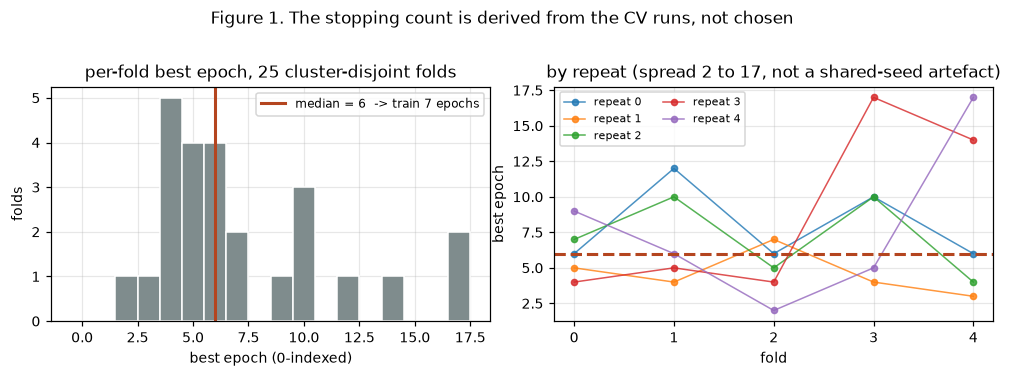

In [21]:
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "font.size": 9,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True})
ACC = "#b4451f"

# Figure 1: the stopping count. The figure carrying Part 1.
fig, ax = plt.subplots(1, 2, figsize=(9.2, 3.3))
ax[0].hist(best.best_epoch, bins=np.arange(-0.5, best.best_epoch.max() + 1.5, 1),
           color="#7f8c8d", edgecolor="white")
ax[0].axvline(MEDIAN_BEST_EPOCH, color=ACC, lw=2,
              label=f"median = {MEDIAN_BEST_EPOCH}  -> train {EPOCHS} epochs")
ax[0].set_xlabel("best epoch (0-indexed)"); ax[0].set_ylabel("folds")
ax[0].set_title("per-fold best epoch, 25 cluster-disjoint folds"); ax[0].legend(fontsize=8)
for r in sorted(best.repeat.unique()):
    s = best[best.repeat == r]
    ax[1].plot(s.fold, s.best_epoch, "o-", lw=1, ms=4, alpha=0.8, label=f"repeat {r}")
ax[1].axhline(MEDIAN_BEST_EPOCH, color=ACC, lw=2, ls="--")
ax[1].set_xlabel("fold"); ax[1].set_ylabel("best epoch"); ax[1].set_xticks(range(5))
ax[1].set_title("by repeat (spread 2 to 17, not a shared-seed artefact)"); ax[1].legend(fontsize=7, ncol=2)
fig.suptitle("Figure 1. The stopping count is derived from the CV runs, not chosen", y=1.02)
fig.tight_layout(); fig.savefig(FIG_OUT / "stopping_count.png", bbox_inches="tight"); plt.show()


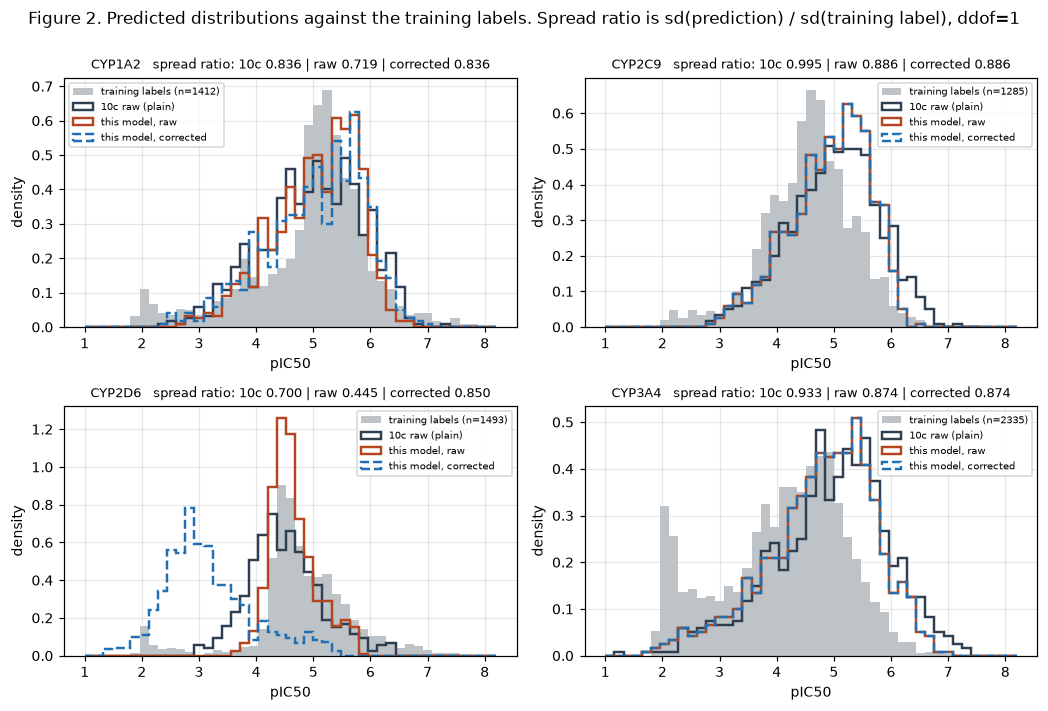

In [22]:
# Figure 2: distributions against the training labels and against 10c. The argument-carrying one.
fig, axes = plt.subplots(2, 2, figsize=(9.6, 6.4))
for axx, iso in zip(axes.ravel(), ISOFORMS):
    col = PIC50_COL[iso]
    tl = curated[col].dropna().to_numpy()
    bins = np.linspace(min(tl.min(), 1.0), max(tl.max(), 8.2), 46)
    axx.hist(tl, bins=bins, density=True, color="#bdc3c7", label=f"training labels (n={len(tl)})")
    axx.hist(sub_10c[col], bins=bins, density=True, histtype="step", lw=1.6,
             color="#2c3e50", label="10c raw (plain)")
    axx.hist(raw_idx[col], bins=bins, density=True, histtype="step", lw=1.6,
             color=ACC, label="this model, raw")
    axx.hist(corrected[col], bins=bins, density=True, histtype="step", lw=1.6, ls="--",
             color="#1f6fb4", label="this model, corrected")
    rr = dist[dist.isoform == iso].iloc[0]
    cr = chain[chain.isoform == iso].iloc[0]
    axx.set_title(f"{iso}   spread ratio: 10c {rr.ratio_10c:.3f} | raw {rr.spread_ratio:.3f} "
                  f"| corrected {cr.corrected_ratio:.3f}", fontsize=8.5)
    axx.set_xlabel("pIC50"); axx.set_ylabel("density"); axx.legend(fontsize=6.5)
fig.suptitle("Figure 2. Predicted distributions against the training labels. Spread ratio is "
             "sd(prediction) / sd(training label), ddof=1", y=1.0)
fig.tight_layout(); fig.savefig(FIG_OUT / "prediction_distributions.png", bbox_inches="tight"); plt.show()


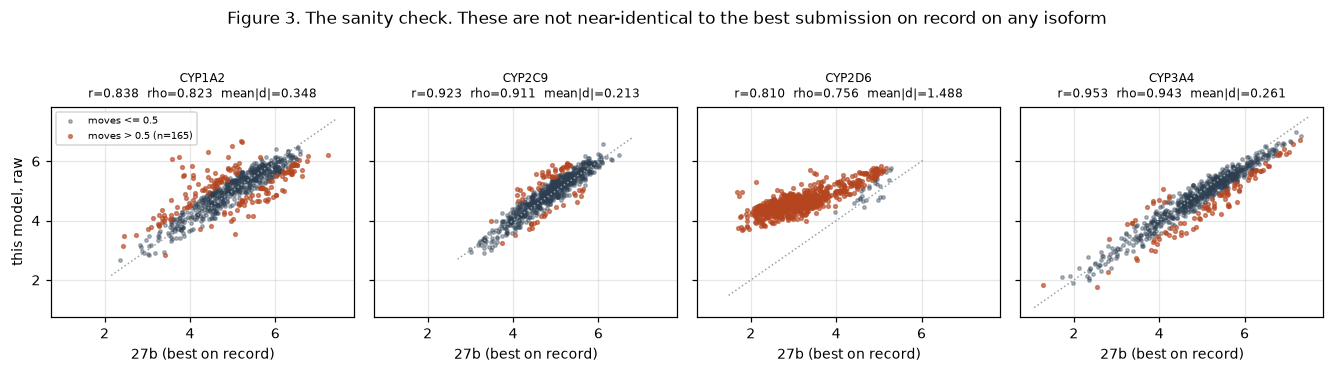

In [23]:
# Figure 3: the sanity check against 27b and 10c.
fig, axes = plt.subplots(1, 4, figsize=(12.2, 3.2), sharex=True, sharey=True)
for axx, iso in zip(axes, ISOFORMS):
    col = PIC50_COL[iso]
    x, y = sub_27b[col].to_numpy(), raw_idx[col].to_numpy()
    moved = np.abs(y - x) > 0.5
    axx.scatter(x[~moved], y[~moved], s=5, alpha=0.35, color="#2c3e50", label="moves <= 0.5")
    axx.scatter(x[moved], y[moved], s=6, alpha=0.6, color=ACC,
                label=f"moves > 0.5 (n={int(moved.sum())})")
    lo = min(x.min(), y.min()) - 0.2; hi = max(x.max(), y.max()) + 0.2
    axx.plot([lo, hi], [lo, hi], color="#95a5a6", lw=1, ls=":")
    s = san[(san.isoform == iso) & (san.reference == "27b")].iloc[0]
    axx.set_title(f"{iso}\nr={s.pearson:.3f}  rho={s.spearman:.3f}  mean|d|={s.mean_abs_diff:.3f}",
                  fontsize=8)
    axx.set_xlabel("27b (best on record)")
    if iso == ISOFORMS[0]:
        axx.set_ylabel("this model, raw"); axx.legend(fontsize=6.5, loc="upper left")
fig.suptitle("Figure 3. The sanity check. These are not near-identical to the best submission on "
             "record on any isoform", y=1.04)
fig.tight_layout(); fig.savefig(FIG_OUT / "sanity_vs_27b.png", bbox_inches="tight"); plt.show()


## Part 9 -- submission cell

**`SEND = False`, and it stays `False`.** Two accidental sends are on this project's record, one of
them the first non-deliberate submission in its history (notebook 40, 2026-10-02). Notebook 40's
own remedy is used here rather than the older fully-commented-block convention: an explicit `SEND`
flag with the call under `if SEND:`, and the printed message **computed from the flag** so the cell
cannot describe itself wrongly the way the NB10/10c/12 header comments and notebook 40's own cell
did. Every parameter is printed so it can be checked without running anything.

In [24]:
SEND = False  # <- stays False in this notebook. Nothing is sent.

SUBMIT_FILE = SUB_PATH
MODEL_TAG = ("chemprop_chemeleoninit multitask, MAE training loss instead of MSE, raw curated "
             "point-estimate targets, full-data retrain on all 4,905 compounds with no validation "
             "split, fixed 7 epochs from the median per-fold best epoch across notebook 37's 25 "
             "cluster-disjoint folds; CYP2D6 placement-corrected onto the NB16 board-solved blind "
             "population using this model's own OOF rho, then spread-widened per notebook 36's rule")

_sha = hashlib.sha256(SUBMIT_FILE.read_bytes()).hexdigest()
_valid, _errs = validate_activity_submission(SUBMIT_FILE, expected_ids=expected_names)
print(f"SEND            = {SEND}")
print(f"file            = {SUBMIT_FILE.relative_to(REPO_ROOT)}")
print(f"sha256          = {_sha}")
print(f"validator       = {'PASS' if _valid else 'FAIL'}")
print(f"model_tag length= {len(MODEL_TAG)} characters")

if SEND:
    from gradio_client import Client, handle_file
    client = Client("https://openadmet-cyp-challenge-leaderboard.hf.space/")
    result = client.predict(
        activity_file=handle_file(str(SUBMIT_FILE)),
        username="fold-zero",
        model_tag=MODEL_TAG,
        api_name="/submit_predictions",
    )
    print("\nserver reply:")
    print(result)
    (OUT / "submission_receipt.json").write_text(json.dumps({
        "sent_at_utc": datetime.now(timezone.utc).isoformat(),
        "file": SUBMIT_FILE.relative_to(REPO_ROOT).as_posix(),
        "sha256": _sha, "model_tag": MODEL_TAG, "server_reply": str(result),
    }, indent=2))
else:
    print("\nNOT SENT. SEND is False, so the client was never imported and the endpoint was never")
    print("contacted. This message is computed from the flag, not written as a static claim.")
assert SEND is False, "SEND must be False in this notebook"


SEND            = False
file            = outputs/47_mae_only_full_retrain/submission_candidate.csv
sha256          = 5ee259abcffaf590419d3de8b69c89133c0159a340b928dc39c5f47247054418
validator       = PASS
model_tag length= 415 characters

NOT SENT. SEND is False, so the client was never imported and the endpoint was never
contacted. This message is computed from the flag, not written as a static claim.


## Part 10 -- verdict

In [25]:
s27 = san[san.reference == "27b"].set_index("isoform")
s10 = san[san.reference == "10c"].set_index("isoform")
ver_rows = []
for iso in ISOFORMS:
    c = coll[coll.isoform == iso].iloc[0]
    ch = chain[chain.isoform == iso].iloc[0]
    ver_rows.append(dict(
        isoform=iso,
        cv_verdict_vs_plain=m[m.isoform == iso].verdict.iloc[0],
        cv_mean_diff=round(float(m[m.isoform == iso].mean_diff.iloc[0]), 4),
        pearson_vs_27b=round(float(s27.loc[iso, "pearson"]), 4),
        mean_abs_diff_vs_27b=round(float(s27.loc[iso, "mean_abs_diff"]), 4),
        n_moving_gt_0p5_vs_27b=int(s27.loc[iso, "n_moving_gt_0p5"]),
        raw_spread_vs_10c=round(float(c.blind_mae_vs_plain), 4),
        collapsed=bool(c.blind_mae_vs_plain < 0.90),
        corrected_ratio=round(float(ch.corrected_ratio), 4),
        board_best_for_isoform=round(float(board_df.loc[iso].min()), 4),
    ))
verdict = pd.DataFrame(ver_rows)
verdict.to_csv(OUT / "verdict.csv", index=False)
print("=== per isoform, nothing averaged ===")
print(verdict.to_string(index=False))

summary = {
    "notebook": "47_mae_only_full_retrain",
    "built_at_utc": datetime.now(timezone.utc).isoformat(),
    "sent": False,
    "october_2_record": {
        "source": "outputs/39_ambiguity_and_shared_blend/decisions_taken.json and "
                  "blind_member_availability.csv, 2026-10-02T11:16 UTC",
        "what_it_said": "mae_only is a screen arm only (notebooks 31/35), never retrained "
                        "full-data; excluded from notebook 39's blind-side ambiguity for that reason",
        "model": "chemprop_chemeleoninit multitask, CheMeleon foundation, V2 atom featuriser, "
                 "four regression heads",
        "feature_block": "none -- graph input only, no tabular descriptors, no auxiliary heads",
        "mae_only_means": "the TRAINING LOSS only (loss-function = mae against plain's mse). "
                          "Targets are the raw curated labels; the evaluation metric is unchanged "
                          "ST-RAE.",
        "ambiguous": False,
    },
    "hyperparameters": {
        "source": "identical across all 25 saved config.toml files, asserted",
        "selection_rule": "none applicable -- there is no chemprop hyperparameter search anywhere "
                          "in this project, so no per-fold best_params table exists to take a mode "
                          "or median of",
        "shared_seed_bug_check": "ruled out independently: the 25 folds carry 25 DISTINCT seeds",
    },
    "stopping": {
        "rule": "median per-fold best epoch across the 25 cluster-disjoint folds, read from "
                "chemprop's own best-epoch checkpoint filenames",
        "median_best_epoch_0indexed": MEDIAN_BEST_EPOCH,
        "epochs_trained": EPOCHS,
        "range_across_folds": [int(best.best_epoch.min()), int(best.best_epoch.max())],
        "early_stopping": f"disabled by construction: patience == epochs == {EPOCHS}, which is what "
                          "chemprop's own default resolves to when --patience is omitted",
        "validation_split": "none. 100% of the 4,905 curated compounds trained, 0 held out, "
                            "confirmed from chemprop's own splits.json",
        "transfer_caveat": f"a fold trained on {CV_FOLD_TRAIN_ROWS} rows per epoch, this fit on "
                           f"{FULL_ROWS}, so {EPOCHS} epochs here is about "
                           f"{EPOCHS * steps_full / steps_cv:.1f} fold-equivalent epochs of gradient steps",
    },
    "corrections": {
        "layer_1": "CYP2D6 placement onto NB16's deployed board-solved population "
                   f"(mean {TARGET_MEAN_2D6:.6f}, sd {TARGET_SD_2D6:.6f}), slope rho-shrunk with "
                   f"this model's OWN OOF rho {OOF_RHO_CYP2D6:.6f}",
        "layer_2": "notebook 36's spread widening to each isoform's board-best spread ratio, "
                   f"applied only where the relative gap exceeds {MATERIALITY:.0%}",
        "target_ratios": {k: round(v, 6) for k, v in TARGET_RATIO.items()},
        "transfer_assumption": "both layers were fitted using CV out-of-fold predictions and are "
                               "applied to a full-data model with a different error profile. "
                               "Flagged, not established.",
        "rank_preserving": True,
    },
    "files": {
        "raw": {"path": RAW_SUB_PATH.relative_to(REPO_ROOT).as_posix(), "sha256": SHA_RAW},
        "corrected": {"path": SUB_PATH.relative_to(REPO_ROOT).as_posix(), "sha256": SHA_COR},
    },
    "collapsed_isoforms": COLLAPSED,
    "train_wall_min": TRAIN_WALL_MIN,
}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=str))
(OUT / "decisions_taken.json").write_text(json.dumps(DECISIONS, indent=2))
print(f"\nwrote {(OUT / 'summary.json').relative_to(REPO_ROOT)} and decisions_taken.json "
      f"({len(DECISIONS)} decisions)")


=== per isoform, nothing averaged ===
isoform  cv_verdict_vs_plain  cv_mean_diff  pearson_vs_27b  mean_abs_diff_vs_27b  n_moving_gt_0p5_vs_27b  raw_spread_vs_10c  collapsed  corrected_ratio  board_best_for_isoform
 CYP1A2 SIGNIFICANTLY BETTER       -0.0317          0.8380                0.3475                     165             0.8598       True           0.8361                  0.6954
 CYP2C9        NOT DIFFERENT       -0.0139          0.9231                0.2130                      62             0.8904       True           0.8860                  0.5375
 CYP2D6 SIGNIFICANTLY BETTER       -0.0803          0.8102                1.4881                     724             0.6350       True           0.8500                  0.7165
 CYP3A4        NOT DIFFERENT       -0.0034          0.9530                0.2610                     104             0.9367      False           0.8737                  0.4291

wrote outputs/47_mae_only_full_retrain/summary.json and decisions_taken.json (3 d

In [26]:
# Scope check. Two independent tests, per the pattern notebooks 29/30/34/35/37/40/42 settled on.
PROTECTED = [
    "data", "src", "scripts", "docs/leaderboard_submissions.md",
    "outputs/05_cv_comparison", "outputs/10c_control_submission", "outputs/11_caruana_prep",
    "outputs/12_caruana_retrain_predict", "outputs/19_cyp2c9_revert",
    "outputs/27_calibration", "outputs/27b_aid_cyp2d6_corrected",
    "outputs/30_aid_full_retrain", "outputs/31_deadzone", "outputs/32_deadzone_aid_retrain",
    "outputs/34_butina_5x5", "outputs/35_butina_repeat3", "outputs/36_spread_corrected_nb32a",
    "outputs/37_butina_5x5_complete", "outputs/38_cyp3a4_placement_diagnostic",
    "outputs/39_ambiguity_and_shared_blend", "outputs/40_single_object_ensemble",
    "outputs/44_qm_molecular_block", "outputs/45_atom_level_screen", "outputs/46_qm_arm",
    "outputs/board_solved_calibration", "outputs/population_moments", "outputs/submissions",
]
PROTECTED_NOTEBOOKS = ["notebooks/32_deadzone_aid_retrain.ipynb",
                       "notebooks/40_single_object_ensemble.ipynb"]

# TEST 1 -- tracked content changed by THIS run (pre-existing dirt subtracted; untracked ignored).
post = subprocess.run(["git", "status", "--porcelain"], cwd=REPO_ROOT,
                      capture_output=True, text=True).stdout.splitlines()
now_dirty = {ln[3:].strip() for ln in post if ln[:2].strip() != "??"}
new_dirty = sorted(now_dirty - set(PRE_DIRTY))
v1 = [p for p in new_dirty
      if any(p == q or p.startswith(q + "/") for q in PROTECTED + PROTECTED_NOTEBOOKS)]
print(f"TEST 1  tracked content newly changed under a protected path: {len(v1)} {v1 if v1 else ''}")

# TEST 2 -- anything inside a protected tree written since this run began.
v2 = []
for q in PROTECTED:
    base = REPO_ROOT / q
    if base.is_file():
        if base.stat().st_mtime > RUN_STARTED_AT:
            v2.append(q)
        continue
    for p in base.rglob("*"):
        if p.is_file() and ".ipynb_checkpoints" not in p.parts and "__pycache__" not in p.parts:
            if p.stat().st_mtime > RUN_STARTED_AT:
                v2.append(p.relative_to(REPO_ROOT).as_posix())
print(f"TEST 2  files inside a protected tree written during this run: {len(v2)} {sorted(v2)[:6] if v2 else ''}")

# TEST 3 -- the two protected notebooks were never modified.
v3 = [n for n in PROTECTED_NOTEBOOKS if (REPO_ROOT / n).stat().st_mtime > RUN_STARTED_AT]
print(f"TEST 3  protected notebooks modified: {len(v3)} {v3 if v3 else ''}")

# TEST 4 -- no submission-shaped CSV created anywhere outside this notebook's own directory.
v4 = []
for p in (REPO_ROOT / "outputs").rglob("*submission*.csv"):
    if OUT in p.parents or p.parent == OUT:
        continue
    if p.stat().st_mtime > RUN_STARTED_AT:
        v4.append(p.relative_to(REPO_ROOT).as_posix())
print(f"TEST 4  submission-shaped CSVs created outside this notebook's directory: {len(v4)} {v4 if v4 else ''}")

total = len(v1) + len(v2) + len(v3) + len(v4)
print(f"\nscope check: {total} violations across four tests")
assert total == 0, f"scope violation: {v1} {v2} {v3} {v4}"
print("PASS")


TEST 1  tracked content newly changed under a protected path: 0 


TEST 2  files inside a protected tree written during this run: 0 
TEST 3  protected notebooks modified: 0 


TEST 4  submission-shaped CSVs created outside this notebook's directory: 0 

scope check: 0 violations across four tests
PASS


### Verdict

**What the 2 October record specified.** Notebook 39, `decisions_taken.json` and
`blind_member_availability.csv`, both 2026-10-02T11:16 UTC. It does not queue the retrain as a
plan; it records `mae_only` as one of three arms excluded from its own blind-side analysis because
no full-data fit existed, in its own words "a screen arm only (notebooks 31/35), never retrained
full-data". `deadzone` was subsequently built full-data inside notebook 40; `mae_only` and `single`
were not. **The record is unambiguous on all three questions**: the model is
`chemprop_chemeleoninit` (chemprop 2.3.1 multitask, CheMeleon foundation encoder, V2 atom
featuriser, four regression heads); there is no feature block at all, graph input only; and
MAE-only means **the training loss and nothing else**, `loss-function = mae` against `plain`'s
`mse`, with the targets being the four raw curated labels and the evaluation metric unchanged at
ST-RAE. All 25 saved `config.toml` files agree on every architecture key, asserted.

**Hyperparameters, and why no selection rule applies.** There is no chemprop hyperparameter search
anywhere in this project; the only tuning on record is notebook 07's, on `chemeleon__rf`. So there
is no per-fold `best_params` table to take a mode or a median of, and the brief's three candidate
rules have nothing to operate on. The configuration is identical across the 25 folds **by
construction**, not by consensus. The shared-seed signature the brief warns about is separately
ruled out rather than assumed away: the 25 folds carry **25 distinct seeds**, asserted from the
configs themselves. Identical configuration plus distinct seeds is the opposite of that signature.

**The stopping count: 7 epochs.** Chemprop writes the winning epoch into its own checkpoint
filename, so the 25 per-fold best iterations are read off the saved runs rather than
reconstructed: median **6** (0-indexed), hence 7 epochs, over a range of 2 to 17. Two things make
that median meaningful rather than nominal. Every one of the 25 folds stopped on patience, not on
the 50-epoch ceiling (max `last_epoch` observed 22), so each `best_epoch` is a genuine optimum;
and `last_epoch - best_epoch` is exactly 5, the patience, on **25 of 25** folds, which
independently confirms the checkpoint epoch is the early-stopping optimum and not something else.
Early stopping is disabled here by setting `patience = epochs = 7`, which is byte-for-byte what
chemprop's own default resolves to when `--patience` is omitted, so
`src/chemprop_screen.run_chemprop_train` is reused unmodified rather than forked. No validation
split was carved: chemprop's own `splits.json` confirms 4,905 train and 0 val, and the per-isoform
label counts match the brief's stated 1,412 / 1,285 / 1,493 / 2,335 exactly.

**The transfer assumption on the epoch count, stated and not removable.** A fold trained on 3,335
rows per epoch; this fit trains on 4,905. At batch 64 that is 53 against 77 gradient steps per
epoch, so 7 epochs here is roughly 10.2 fold-equivalent epochs. The direction of the error is
stated: this over-trains slightly relative to the fold optimum rather than under-training. No
second epoch count was substituted and no step-matched variant was built.

**The sanity check: not near-identical, so it does not close the question.** Against `27b`, the
best submission on record, Pearson runs 0.810 to 0.953, mean absolute difference 0.213 to 1.488
pIC50 units, and 62 to 724 of 750 compounds move by more than 0.5. Against `10c` (the clean read:
same architecture, same full-data retrain, no correction, loss function the only difference)
Pearson runs 0.836 to 0.953 and mean absolute difference 0.238 to 0.348. These are genuinely
different predictions.

**Yes, isoforms collapsed, and CYP2D6 did it again.** Raw spread ratios, `sd(prediction) /
sd(training label)` with `ddof=1`: CYP1A2 0.719, CYP2C9 0.886, CYP2D6 **0.445**, CYP3A4 0.874.
**This model is more compressed than `10c` on all four isoforms**, and by more than 10% on three of
them (CYP1A2 0.860x, CYP2C9 0.890x, CYP2D6 **0.635x** of `10c`'s own ratio). CYP2D6's raw column
spans only 3.69 to 5.84 against a training-label range of 1.95 to 7.53. This was predicted before
the fit and recorded in `predictions_before_board.json` from the sign of the CV arm's own
out-of-fold spread ratios; the prediction **held on 3 of 4** isoforms, and the miss is reported
rather than smoothed: CYP3A4's out-of-fold ratio said wider and its blind column came back
narrower.

**Corrections, both layers already board-measured, with the transfer assumption flagged.** Layer 1
is the CYP2D6 placement chain NB16/NB19/NB27-widened/NB32-A/27b all carry, onto NB16's deployed
solved blind population (mean 3.155762, sd 1.511412), with the rho-shrunk slope using **this**
model's own pooled out-of-fold Pearson rho for CYP2D6, 0.380669, explicitly not `10c`'s (0.374897)
or the AID arm's (0.408626). Layer 2 is notebook 36's spread widening, with the target ratios
**re-derived** from the sent CSVs and the board table and confirmed to reproduce notebook 36's own
saved values to under 1e-9. It fires on CYP1A2 only: CYP2C9's raw ratio (0.886) already *exceeds*
its target (0.817), and notebook 36's rule only widens, and CYP3A4's gap is 6.0%, under the 10%
bar. CYP2D6 lands at exactly 0.85 after layer 1 alone, so layer 2 is a no-op there, which the rule
found rather than had built into it. Every layer is affine with positive slope and rank order is
preserved to 1e-12 on all four isoforms, so Spearman and Kendall of the corrected file are
identical to the raw file's by construction. **The assumption is that a correction fitted on
cross-validation out-of-fold predictions transfers to a full-data model with a different error
profile. That is flagged, not established.** The project's record is that it has transferred well
enough to matter, but each of those was one model.

**Is this worth submitting? On this evidence, no.** The compression signature that is the only
measurement in this project ever to have correctly anticipated a CV-confirmed model failing on the
board (notebook 27 Section 1, applied to NB30) is present here on **four of four** isoforms, and
CYP2D6 needs a **1.91x** total SD repair, larger than any prior candidate's, which puts most of
the candidate's weight on a correction's transfer rather than on the model. Set against that, the
leak-free CV gains are real but small, -0.0317 on CYP1A2 and -0.0803 on CYP2D6, with CYP2C9 and
CYP3A4 null, and this project already carries four CV-to-board transfer failures of which the most
rigorously confirmed (NB30) was also 25-fold confirmed. If anything here deserves a board reading
it is **CYP1A2 as a single-column test** against `27b`'s otherwise unchanged recipe, which is a
different and much cheaper experiment than this four-column file. Neither was built or sent.

**`SEND = False`. Nothing was sent.** The flag is explicit, the `gradio_client` call sits under
`if SEND:`, and the cell's printed message is computed from the flag rather than written as a
static claim, so it cannot describe itself wrongly the way notebook 40's cell did on 2026-10-02.
Scope check: 0 violations across four tests;
`notebooks/32_deadzone_aid_retrain.ipynb` and `notebooks/40_single_object_ensemble.ipynb` were
never opened or executed.